In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# ============================================================
# CELL 1b — scan all CSVs under /content and load the correct freight file
# ============================================================
import os, glob, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)

# ---- 1. list every CSV and its columns ----
print("=== all CSVs under /content ===")
found = sorted(glob.glob("/content/**/*.csv", recursive=True))
for p in found:
    try:
        head = pd.read_csv(p, nrows=1)
        size = os.path.getsize(p) / 1e6
        print(f"\n{p}   [{size:.2f} MB, {len(head.columns)} cols]")
        print("   cols:", ", ".join(map(str, head.columns)))
    except Exception as e:
        print(f"\n{p}   ✗ could not read: {e}")

# ---- 2. pick the freight file by column signature ----
REQUIRED = {"load_id", "pickup", "delivery", "distance", "equipment",
            "weight", "date", "market_index", "quote_signal", "posted_rate"}

def is_freight(p):
    try:
        return REQUIRED.issubset(set(map(str, pd.read_csv(p, nrows=1).columns)))
    except Exception:
        return False

candidates = [p for p in found if is_freight(p)]
print("\n=== freight file candidates ===")
print(candidates if candidates else "❌ none found")

# ---- if nothing is found, set the path here manually ----
DATA_PATH = candidates[0] if candidates else None
# DATA_PATH = "/content/sample_data/train-test.csv"      # ← uncomment and set the correct path if needed

if DATA_PATH is None:
    print("\nNo freight file in the list above → upload train-test.csv via the Colab Files panel (left side),")
    print("then run this cell again. (Or use the upload widget below.)")
    try:
        from google.colab import files as _cf
        up = _cf.upload()
        cand = [p for p in up if is_freight(p)]
        DATA_PATH = cand[0] if cand else None
    except Exception:
        pass

if DATA_PATH is None:
    raise FileNotFoundError("freight data not found")

# ---- 3. load ----
df = pd.read_csv(DATA_PATH)
N = len(df)
print("\n" + "="*70)
print(f"✓ LOADED: {DATA_PATH}")
print(f"  shape: {df.shape[0]:,} rows × {df.shape[1]} cols | memory {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
print(f"  columns: {list(df.columns)}")
print("="*70)
print("\nfirst 3 rows (transposed):")
print(df.head(3).T.to_string())

=== all CSVs under /content ===

/content/sample_data/california_housing_test.csv   [0.30 MB, 9 cols]
   cols: longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income, median_house_value

/content/sample_data/california_housing_train.csv   [1.71 MB, 9 cols]
   cols: longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income, median_house_value

/content/sample_data/mnist_test.csv   [18.29 MB, 785 cols]
   cols: 7, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.10, 0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.20, 0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.30, 0.31, 0.32, 0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.40, 0.41, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.50, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.60, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.70, 0.71, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.80, 0.81, 0

Saving december-chart-inputs.csv to december-chart-inputs.csv
Saving freight-rate-ml-assessment.pdf to freight-rate-ml-assessment.pdf
Saving readme.md to readme.md
Saving requirements.txt to requirements.txt
Saving score.py to score.py
Saving train-test.csv to train-test.csv
Saving validation.csv to validation.csv
Saving validation-predictions-template.csv to validation-predictions-template.csv

✓ LOADED: train-test.csv
  shape: 48,000 rows × 14 cols | memory 17.3 MB
  columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']

first 3 rows (transposed):
                       0             1             2
load_id        TR-000001     TR-000002     TR-000003
pickup          Richmond      Richmond  Philadelphia
delivery       Baltimore  Philadelphia     Green Bay
pickup_lat      38.09122      38.09122      39.22317
pickup_lon     -76.78906     -76.78906  

In [ ]:
# ============================================================
# CELL 2/N — DUPLICATES · PAIR (LANE) STRUCTURE · MISSINGNESS
# No verdicts — measurement only.
# ============================================================
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 40)

if "df" not in globals():                      # auto-reload if the kernel restarted
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p)
            print("reloaded:", p)
            break
N = len(df)

# ---------------------------------------------------------------
print("=" * 70)
print("A. IDENTITY / ORDERING")
print("=" * 70)
print("rows:", f"{N:,}")
print("load_id unique:", df["load_id"].is_unique)
ids = df["load_id"].astype(str).str.extract(r"(\d+)$")[0].astype(int)
print("load_id numeric part: first =", ids.iloc[0], " last =", ids.iloc[-1])
print("load_id steps strictly +1:", bool((ids.diff().dropna() == 1).all()))
d = pd.to_datetime(df["date"], errors="coerce")
print("date parses:", f"{d.notna().mean():.1%}", "| range:", d.min(), "->", d.max())
print("rows monotonically increasing in date:", d.is_monotonic_increasing)
print("distinct dates:", d.dt.date.nunique(), "| rows/day: min =", df.groupby(d.dt.date).size().min(),
      " max =", df.groupby(d.dt.date).size().max())

# ---------------------------------------------------------------
print("\n" + "=" * 70)
print("B. DUPLICATES")
print("=" * 70)
print("exact duplicate rows (all columns):", df.duplicated().sum())
feat_cols = [c for c in df.columns if c not in ("load_id", "posted_rate")]
print("exact duplicates on features only (excl. load_id + target):", df.duplicated(feat_cols).sum())

keys = [
    ["pickup", "delivery"],
    ["pickup", "delivery", "date"],
    ["pickup", "delivery", "equipment", "date"],
    ["pickup", "delivery", "equipment", "weight", "date"],
]
print("\nrows sharing the same values on a key (NaN treated as its own group):")
for k in keys:
    g = df.groupby(k, dropna=False).size()
    print(f"  {str(k):58s} rows={df.duplicated(k, keep=False).sum():6,d}  groups={len(g):6,d}  max_group={g.max()}")

# ---------------------------------------------------------------
print("\n" + "=" * 70)
print("C. PAIR (LANE) STRUCTURE")
print("=" * 70)
n_pickup, n_delivery = df["pickup"].nunique(), df["delivery"].nunique()
print(f"pickup values: {n_pickup} | delivery values: {n_delivery} | possible ordered pairs: {n_pickup*(n_delivery-1):,}")
lane = df.groupby(["pickup", "delivery"]).size()
print(f"observed lanes: {len(lane):,}")
print(f"rows per lane -> mean {lane.mean():.2f} | p25 {lane.quantile(.25):.0f} | median {lane.median():.0f} "
      f"| p75 {lane.quantile(.75):.0f} | max {lane.max()}")
print("lanes with 1 row:", int((lane == 1).sum()), "| with >= 100 rows:", int((lane >= 100).sum()))
print("\n10 busiest lanes:")
print(lane.nlargest(10).to_string())

# ---------------------------------------------------------------
print("\n" + "=" * 70)
print("D. MISSINGNESS")
print("=" * 70)
miss_cols = [c for c in df.columns if df[c].isna().any()]
print("columns with missing values:", miss_cols if miss_cols else "none")
if miss_cols:
    tbl = pd.DataFrame({
        "n_missing": df[miss_cols].isna().sum(),
        "pct_missing": (df[miss_cols].isna().mean() * 100).round(3),
    })
    print("\n" + tbl.to_string())

    print("\nmissing COUNT by month:")
    print(df.groupby(d.dt.to_period("M"))[miss_cols].apply(lambda x: x.isna().sum()).to_string())
    print("\nmissing RATE (%) by month:")
    print(df.groupby(d.dt.to_period("M"))[miss_cols].apply(lambda x: x.isna().mean() * 100).round(2).to_string())

    print("\n5 dates with most missing rows (any column):")
    byday = df.groupby(d.dt.date)[miss_cols].apply(lambda x: x.isna().sum()).sum(axis=1)
    print(byday.nlargest(5).to_string())

    for c in miss_cols:
        print(f"\n--- '{c}' : does the missing group differ from the rest? ---")
        m = df[c].isna()
        print(f"  n_missing = {int(m.sum())}")
        if pd.api.types.is_numeric_dtype(df["posted_rate"]):
            print(f"  posted_rate mean   missing={df.loc[m, 'posted_rate'].mean():10.2f}   present={df.loc[~m, 'posted_rate'].mean():10.2f}")
        for cat in ["equipment", "pickup", "delivery"]:
            if cat in df and df[cat].nunique() <= 70:
                top = df.loc[m, cat].value_counts(normalize=True).head(3).round(3).to_dict()
                base = df[cat].value_counts(normalize=True).head(3).round(3).to_dict()
                print(f"  {cat:9s} top-share in missing: {top}   | in full data: {base}")

    # pairwise missingness overlap
    if len(miss_cols) > 1:
        M = df[miss_cols].isna().astype(int)
        print("\nmissing-pattern counts (1 = missing):")
        print(M.value_counts().to_string())

print("\n" + "=" * 70)
print("E. QUESTIONS TO HOLD FOR LATER DECISIONS (no need to answer now - just think)")
print("=" * 70)
print("""
  From B: are there exact duplicates? Which key shows the most overlap?
  From C: how dense are the lanes? And where do 1-row lanes appear?
  From D: is the missingness random, or clustered in some structure? Does the missing group's target differ?
""")
print("\ndf ready for cell 3.")

A. IDENTITY / ORDERING
rows: 48,000
load_id unique: True
load_id numeric part: first = 1  last = 48000
load_id steps strictly +1: True
date parses: 100.0% | range: 2025-01-01 00:00:00 -> 2025-10-31 00:00:00
rows monotonically increasing in date: True
distinct dates: 304 | rows/day: min = 115  max = 198

B. DUPLICATES
exact duplicate rows (all columns): 0
exact duplicates on features only (excl. load_id + target): 0

rows sharing the same values on a key (NaN treated as its own group):
  ['pickup', 'delivery']                                     rows=47,933  groups= 4,014  max_group=39
  ['pickup', 'delivery', 'date']                             rows= 2,396  groups=46,787  max_group=3
  ['pickup', 'delivery', 'equipment', 'date']                rows=   983  groups=47,505  max_group=3
  ['pickup', 'delivery', 'equipment', 'weight', 'date']      rows=     2  groups=47,999  max_group=2

C. PAIR (LANE) STRUCTURE
pickup values: 64 | delivery values: 64 | possible ordered pairs: 4,032
observe

In [ ]:
# ============================================================
# CELL 3/N — SINGLE-COLUMN VALIDITY (numeric + categorical)
# No verdicts — measurement only.
# ============================================================
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 60)

if "df" not in globals():
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p)
            print("reloaded:", p)
            break

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols and c != "date"]
N = len(df)

# ---------------------------------------------------------------
print("=" * 110)
print("A. NUMERIC SUMMARY")
print("=" * 110)
rows = []
for c in num_cols:
    s = df[c]
    v = s.dropna()
    rows.append({
        "column": c, "n_null": int(s.isna().sum()),
        "min": v.min(), "p1": v.quantile(.01), "median": v.median(),
        "p99": v.quantile(.99), "max": v.max(),
        "mean": v.mean(), "std": v.std(),
        "n_neg": int((v < 0).sum()), "n_zero": int((v == 0).sum()),
        "n_unique": int(v.nunique()),
    })
summ = pd.DataFrame(rows).set_index("column")
print(summ.round(3).to_string())

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("B. NEGATIVE / ZERO / INFINITE DETAIL")
print("=" * 110)
found_any = False
for c in num_cols:
    v = df[c].dropna()
    neg = (v < 0)
    if neg.any():
        found_any = True
        print(f"\n--- {c}: {int(neg.sum())} negative values | min={v.min():,.3f} ---")
        print("    distribution of the negative values:")
        print("   ", v[neg].describe(percentiles=[.25, .5, .75]).round(2).to_dict())
        idx = v[neg].index[:4]
        print("    sample rows (full row):")
        print(df.loc[idx].to_string())
        print(f"    if we take abs(): range becomes {v[neg].abs().min():,.0f} .. {v[neg].abs().max():,.0f}"
              f"   | overall abs range {v.abs().min():,.0f} .. {v.abs().max():,.0f}")
    if (v == 0).any():
        found_any = True
        print(f"\n--- {c}: {int((v == 0).sum())} zero values ---")
for c in num_cols:
    if np.isinf(df[c].dropna()).any():
        found_any = True
        print(f"\n--- {c}: INFINITE values present ---")
if not found_any:
    print("none")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("C. MOST-REPEATED VALUES  (placeholder / sentinel detector)")
print("=" * 110)
for c in num_cols:
    vc = df[c].value_counts(dropna=True).head(5)
    share = (vc / N * 100).round(3)
    print(f"\n{c}  (n_unique={df[c].nunique():,})")
    for val, cnt in vc.items():
        print(f"    {val:>14,.4f}  x{cnt:>6,}   ({share[val]}% of all rows)")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("D. DECIMAL PRECISION  (rounded / truncated / mixed?)")
print("=" * 110)
for c in num_cols:
    v = df[c].dropna()
    frac = np.abs(v - np.round(v))
    is_int   = (frac == 0).mean()
    is_1dp   = (np.abs(v * 10 - np.round(v * 10)) < 1e-9).mean()
    is_2dp   = (np.abs(v * 100 - np.round(v * 100)) < 1e-9).mean()
    print(f"  {c:15s} integer-form: {is_int*100:6.2f}%   <=1dp: {is_1dp*100:6.2f}%   <=2dp: {is_2dp*100:6.2f}%")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("E. CATEGORICAL COLUMNS")
print("=" * 110)
for c in cat_cols + ["date"]:
    s = df[c].dropna().astype(str)
    u = s.unique()
    print(f"\n--- {c}: n_unique={len(u)} ---")
    if len(u) <= 12:
        print("    values:", sorted(u))
    else:
        print("    first 12 (sorted):", sorted(u)[:12], "...")
    ws = s.str.contains(r"^\s|\s$", regex=True).sum()
    case = s.str.lower().nunique() < s.nunique()
    counts = s.value_counts()
    rare = counts[counts / len(s) < 0.005]
    print(f"    whitespace issues: {int(ws)} | case-inconsistent: {case}")
    if len(counts) > 3:
        print(f"    most common: {counts.head(3).to_dict()}")
        print(f"    rarest:      {counts.tail(3).to_dict()}")
    if len(rare):
        print(f"    levels < 0.5% of rows: {len(rare)} -> {list(rare.index[:8])}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("F. STRING COLUMNS THAT MIGHT BE NUMBERS")
print("=" * 110)
for c in df.columns:
    if df[c].dtype == object:
        conv = pd.to_numeric(df[c], errors="coerce")
        rate = conv.notna().mean()
        if 0.5 < rate and df[c].nunique() > 20:
            print(f"  {c}: {rate:.1%} values convert to numbers")

print("\ndf ready for cell 4.")

A. NUMERIC SUMMARY
              n_null        min        p1     median        p99        max       mean       std  n_neg  n_zero  n_unique
column                                                                                                                  
pickup_lat         0     28.358    28.358     35.295     44.303     44.303     35.648     4.315      0       0        64
pickup_lon         0   -121.698  -119.795    -88.089    -69.500    -69.500    -90.929    13.482  48000       0        63
delivery_lat       0     28.358    28.358     35.295     44.303     44.303     35.641     4.317      0       0        64
delivery_lon       0   -121.698  -119.795    -87.529    -69.500    -69.500    -90.857    13.477  48000       0        63
distance           0     70.000   121.899    953.300   3029.304   3439.800   1135.857   728.564      0       0     21204
weight           300 -47500.000  9801.960  31436.500  47500.000  47500.000  31028.844  9391.441    292       0     23678
market_index 

In [ ]:
# ============================================================
# CELL 4/N — CROSS-COLUMN CONSISTENCY (FIXED, complete)
#   A. city <-> coordinate mapping
#   B. coordinate range (raw numbers)
#   C. distance: minimum anomaly + per-lane stability
#   D. weight: negative vs positive distribution test
#   E. weight: cap / floor structure
# ============================================================
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 60)

if "df" not in globals():
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p); print("reloaded:", p); break
df["date"] = pd.to_datetime(df["date"])

try:
    from scipy import stats
    HAVE_SCIPY = True
except ImportError:
    HAVE_SCIPY = False
    print("(scipy not installed — KS test will be skipped; install scipy to enable it)")

# ---------------------------------------------------------------
print("=" * 110)
print("A. CITY  <->  COORDINATE MAPPING")
print("=" * 110)
for side in ["pickup", "delivery"]:
    latc, lonc = f"{side}_lat", f"{side}_lon"
    nuniq  = df.groupby(side)[[latc, lonc]].nunique().rename(columns={latc: "lat_nuniq", lonc: "lon_nuniq"})
    firsts = df.groupby(side)[[latc, lonc]].first().rename(columns={latc: "lat", lonc: "lon"})
    co = nuniq.join(firsts)
    print(f"\n--- {side}: {len(co)} cities ---")
    print("cities with >1 distinct lat:", int((co.lat_nuniq > 1).sum()),
          "| with >1 distinct lon:", int((co.lon_nuniq > 1).sum()))
    print(f"lat range: [{co.lat.min():.5f}, {co.lat.max():.5f}]  (span {co.lat.max()-co.lat.min():.3f})")
    print(f"lon range: [{co.lon.min():.5f}, {co.lon.max():.5f}]  (span {co.lon.max()-co.lon.min():.3f})")

    # does any full (lat,lon) pair get shared by more than one city?
    coll = co.groupby(["lat", "lon"]).size()
    coll = coll[coll > 1]
    print("full (lat,lon) pair shared by >1 city:", len(coll))
    if len(coll):
        mem = co.reset_index().groupby(["lat", "lon"])[side].apply(list)
        for (la, lo), names in mem.items():
            if len(names) > 1:
                rows = ((df[latc] == la) & (df[lonc] == lo)).sum()
                print(f"    lat={la:.5f} lon={lo:.5f} -> {names}  ({rows:,} rows)")

    # do any cities share only the longitude?
    loneq = co.reset_index().groupby("lon")[side].apply(list)
    loneq = loneq[loneq.apply(len) > 1]
    print("city groups sharing a longitude:", len(loneq))
    for lo, names in loneq.items():
        rows = (df[lonc] == lo).sum()
        print(f"    lon={lo:.5f} -> {list(names)} | {rows:,} rows ({rows/len(df)*100:.2f}%)")

    print(f"    highest-latitude city: {co.loc[co.lat.idxmax()].name} = {co.lat.max():.5f}")
    print(f"    lowest-latitude city:  {co.loc[co.lat.idxmin()].name} = {co.lat.min():.5f}")
    print(f"    westernmost lon: {co.loc[co.lon.idxmin()].name} = {co.lon.min():.5f} | "
          f"easternmost lon: {co.loc[co.lon.idxmax()].name} = {co.lon.max():.5f}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("B. COORDINATE RANGE (raw numbers)")
print("=" * 110)
for c in ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]:
    v = df[c]
    if "lat" in c:
        outside = int(((v < 24) | (v > 50)).sum())
        print(f"  {c:14s} min={v.min():9.4f}  max={v.max():9.4f}  span={v.max()-v.min():8.3f}  "
              f"n_unique={v.nunique():3d}  | outside [24,50]: {outside}")
    else:
        outside = int(((v < -125) | (v > -66)).sum())
        print(f"  {c:14s} min={v.min():9.4f}  max={v.max():9.4f}  span={v.max()-v.min():8.3f}  "
              f"n_unique={v.nunique():3d}  | outside [-125,-66]: {outside}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("C1. distance : GLOBAL MINIMUM")
print("=" * 110)
dmin = df.distance.min()
print(f"global min = {dmin} | rows at min = {int((df.distance == dmin).sum())}")
print(f"smallest 12 unique distances: {sorted(df.distance.unique())[:12]}")
lo = df[df.distance == dmin]
t = lo.groupby(["pickup", "delivery"]).size().sort_values(ascending=False)
print("\nmin-distance rows by lane:")
print(t.to_string())
print("\ndistance span of each min-distance lane:")
sub = df.set_index(["pickup", "delivery"]).loc[t.index]["distance"].groupby(level=[0, 1]).agg(
    ["count", "min", "max", "nunique"])
print(sub.to_string())

print("\n" + "=" * 110)
print("C2. distance : PER-LANE STABILITY")
print("=" * 110)
lane = df.groupby(["pickup", "delivery"])["distance"].agg(["count", "min", "max", "std", "mean"])
lane["n_distinct"] = df.groupby(["pickup", "delivery"])["distance"].nunique()
lane["cv"] = lane["std"] / lane["mean"]
print(f"lanes: {len(lane):,} | >1 distinct distance: {int((lane['n_distinct'] > 1).sum()):,} "
      f"({(lane['n_distinct'] > 1).mean():.1%})")
print("\nCV (std/mean of distance within a lane):")
print(lane["cv"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(5).to_string())
single = lane[lane["n_distinct"] == 1]
print(f"\nlanes where distance never changes: {len(single)} (rows: {int(single['count'].sum()):,})")
print(single.nlargest(8, "count")[["count", "min", "max"]].to_string())
print("\n8 lanes with the highest CV:")
print(lane.nlargest(8, "cv")[["count", "min", "max", "n_distinct", "cv"]].to_string())

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("D. weight : NEGATIVE vs POSITIVE")
print("=" * 110)
w = df["weight"].dropna()
neg, pos = w[w < 0].abs(), w[w >= 0]
print(f"n_negative = {len(neg)} | n_positive = {len(pos)}")
print(f"\n{'quantile':>9} {'|negative|':>14} {'positive':>14} {'diff %':>10}")
for q in [.01, .05, .10, .25, .50, .75, .90, .95, .99]:
    a, b = neg.quantile(q), pos.quantile(q)
    print(f"{q:9.2f} {a:14,.0f} {b:14,.0f} {(a-b)/b*100:9.2f}%")
print(f"\nmean: {neg.mean():,.1f} vs {pos.mean():,.1f}   |   std: {neg.std():,.1f} vs {pos.std():,.1f}")
if HAVE_SCIPY:
    ks = stats.ks_2samp(neg, pos)
    print(f"KS test (|negative| vs positive): statistic = {ks.statistic:.4f}, p-value = {ks.pvalue:.4f}")
print(f"\nposted_rate: neg-weight rows ${df.loc[df.weight < 0, 'posted_rate'].mean():,.2f} "
      f"vs pos-weight rows ${df.loc[df.weight >= 0, 'posted_rate'].mean():,.2f}")
print("negative rows by month:", df[df.weight < 0].groupby(df.date.dt.month).size().to_dict())
print("negative rows by equipment:", df[df.weight < 0].equipment.value_counts().to_dict())

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("E. weight : CAP / FLOOR")
print("=" * 110)
for val in [47500, -47500, 5000, -5000]:
    n = int((w == val).sum())
    print(f"  weight == {val:>7,}: {n:6,d} rows ({n/len(w)*100:.3f}%)")
print(f"\nmax positive = {pos.max():,.0f} | min positive = {pos.min():,.0f}")
bins = [40000, 42500, 45000, 46000, 47000, 47400, 47500, 47501]
print("\npositive weight > 40k histogram (is there a pile-up in the last bin?):")
print(pd.cut(pos[pos > 40000], bins=bins).value_counts().sort_index().to_string())
print("\ncap (47,500) rows by month:", df[df.weight == 47500].groupby(df.date.dt.month).size().to_dict())
print("cap rows by equipment:", df[df.weight == 47500].equipment.value_counts().to_dict())
print("floor (5,000) rows by month:", df[df.weight == 5000].groupby(df.date.dt.month).size().to_dict())

print("\ndf ready for cell 5.")

A. CITY  <->  COORDINATE MAPPING

--- pickup: 64 cities ---
cities with >1 distinct lat: 0 | with >1 distinct lon: 0
lat range: [28.35765, 44.30296]  (span 15.945)
lon range: [-121.69849, -69.50000]  (span 52.198)
full (lat,lon) pair shared by >1 city: 0
city groups sharing a longitude: 1
    lon=-69.50000 -> ['Boston', 'Providence'] | 1,028 rows (2.14%)
    highest-latitude city: Green Bay = 44.30296
    lowest-latitude city:  Tampa = 28.35765
    westernmost lon: San Francisco = -121.69849 | easternmost lon: Boston = -69.50000

--- delivery: 64 cities ---
cities with >1 distinct lat: 0 | with >1 distinct lon: 0
lat range: [28.35765, 44.30296]  (span 15.945)
lon range: [-121.69849, -69.50000]  (span 52.198)
full (lat,lon) pair shared by >1 city: 0
city groups sharing a longitude: 1
    lon=-69.50000 -> ['Boston', 'Providence'] | 1,034 rows (2.15%)
    highest-latitude city: Green Bay = 44.30296
    lowest-latitude city:  Tampa = 28.35765
    westernmost lon: San Francisco = -121.69849

In [ ]:
# ============================================================
# CELL 5/N — GEOMETRY: coordinate <-> distance consistency
#   A. straight-line distance (haversine) from the given coordinates vs the distance column
#   B. how the distance floor (70.0) behaves
#   C. road-factor curve (ratio vs distance)
#   D. city coordinates vs the public GeoName list (automated, reproducible match)
# No verdicts — let the numbers speak.
# ============================================================
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 80)

if "df" not in globals():
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p); print("reloaded:", p); break

R_MILES = 3958.8

def haversine(lat1, lon1, lat2, lon2):
    la1, lo1, la2, lo2 = map(np.radians, [np.asarray(lat1, float), np.asarray(lon1, float),
                                         np.asarray(lat2, float), np.asarray(lon2, float)])
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * R_MILES * np.arcsin(np.sqrt(a))

df = df.copy()
df["hav"] = haversine(df.pickup_lat, df.pickup_lon, df.delivery_lat, df.delivery_lon)
df["ratio"] = df.distance / df.hav

# ---------------------------------------------------------------
print("=" * 110)
print("A. distance  vs  HAVERSINE( given coordinates )")
print("=" * 110)
print("ratio = distance / haversine")
print(df.ratio.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(4).to_string())
print(f"\nratio < 1.00 (road distance shorter than straight-line = abnormal): {int((df.ratio < 1).sum())}")
print(f"ratio < 1.05: {int((df.ratio < 1.05).sum())} | ratio > 1.60: {int((df.ratio > 1.60).sum())} | > 2.0: {int((df.ratio > 2).sum())}")
print(f"corr(distance, haversine) = {np.corrcoef(df.distance, df.hav)[0,1]:.6f}")
print("\n5 rows with the smallest ratio:")
print(df.nsmallest(5, "ratio")[["load_id", "pickup", "delivery", "distance", "hav", "ratio"]].round(3).to_string(index=False))
print("\n5 rows with the largest ratio:")
print(df.nlargest(5, "ratio")[["load_id", "pickup", "delivery", "distance", "hav", "ratio"]].round(3).to_string(index=False))

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("B. distance : FLOOR (min value = 70.0)")
print("=" * 110)
floor_val = df.distance.min()
at_floor = df[df.distance == floor_val]
print(f"min distance = {floor_val} | rows exactly at it: {len(at_floor)}")
print(f"those rows' haversine: min={at_floor.hav.min():.2f}  median={at_floor.hav.median():.2f}  max={at_floor.hav.max():.2f}")
print(f"those rows' ratio    : min={at_floor.ratio.min():.2f}  median={at_floor.ratio.median():.2f}  max={at_floor.ratio.max():.2f}")
print("\nwhich lanes sit at the floor, and what does haversine say for them?")
g = at_floor.groupby(["pickup", "delivery"]).agg(n=("distance", "size"), hav_med=("hav", "median"))
print(g.round(2).to_string())

print("\nrows just ABOVE the floor (70 < distance <= 90):")
near = df[(df.distance > floor_val) & (df.distance <= 90)]
print(f"  n = {len(near)} | their haversine: median {near.hav.median():.2f}, max {near.hav.max():.2f}")
print(f"  ratio: min {near.ratio.min():.2f} median {near.ratio.median():.2f} max {near.ratio.max():.2f}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("C. ROAD-FACTOR CURVE (ratio vs distance)")
print("=" * 110)
buckets = [(70, 100), (100, 200), (200, 300), (300, 500), (500, 750), (750, 1000),
           (1000, 1500), (1500, 2000), (2000, 3000), (3000, 3500)]
print(f"{'distance bucket':>18} {'n':>7} {'ratio p10':>10} {'ratio p50':>10} {'ratio p90':>10}")
for lo, hi in buckets:
    s = df[(df.distance > lo) & (df.distance <= hi)]
    if len(s) == 0: continue
    print(f"{f'{lo}-{hi}':>18} {len(s):7,d} {s.ratio.quantile(.10):10.3f} {s.ratio.quantile(.50):10.3f} {s.ratio.quantile(.90):10.3f}")

print("\nlane-level (n>=5 rows per lane): median distance vs median haversine")
lane = df.groupby(["pickup", "delivery"]).agg(n=("distance", "size"), hav=("hav", "median"),
                                              dist=("distance", "median"), std=("distance", "std"))
lane = lane[lane.n >= 5].copy()
lane["lane_ratio"] = lane.dist / lane.hav
print(lane.lane_ratio.describe(percentiles=[.05, .25, .5, .75, .95]).round(4).to_string())
print("\ntop 6 lanes by lane_ratio | bottom 6 lanes by lane_ratio:")
print(pd.concat([lane.nlargest(6, "lane_ratio"), lane.nsmallest(6, "lane_ratio")]).round(2).to_string())

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("D. CITY COORDINATES vs PUBLIC REFERENCE (GeoName, automated match)")
print("=" * 110)
# Reference = the public GeoName cities15000 list (source: geonames.org, CC BY 4.0),
# downloaded at runtime. The match is fully automated, so anyone can reproduce it:
#   1) exact name match (case-insensitive) on name or asciiname
#   2) otherwise a prefix match on "CITY-" / "CITY " (e.g. Lexington -> Lexington-Fayette)
#   3) among all candidates, keep the highest-population place (deterministic tie-break)
# The full match table is printed so every single match can be re-audited.

import urllib.request, zipfile, io

URL = "https://download.geonames.org/export/dump/cities15000.zip"
CACHE = "/content/cities15000.zip" if os.path.isdir("/content") else "/tmp/cities15000.zip"

try:
    if not os.path.exists(CACHE):
        print(f"downloading {URL} ...")
        req = urllib.request.Request(URL, headers={"User-Agent": "colab-audit/1.0"})
        with urllib.request.urlopen(req, timeout=120) as resp, open(CACHE, "wb") as fh:
            fh.write(resp.read())

    with zipfile.ZipFile(CACHE) as zf:
        inner = zf.namelist()[0]
        geo_rows = []
        with zf.open(inner) as fh:
            for line in io.TextIOWrapper(fh, encoding="utf-8"):
                p = line.rstrip("\n").split("\t")
                if len(p) < 15 or p[8] != "US":
                    continue
                geo_rows.append({"name": p[1], "asciiname": p[2],
                                 "lat": float(p[4]), "lon": float(p[5]),
                                 "admin1": p[10], "pop": int(p[14]) if p[14] else 0})
    geo = pd.DataFrame(geo_rows)
    print(f"reference loaded: {len(geo):,} US places (GeoName cities15000, CC BY 4.0)")

    def geoname_match(q):
        ql = q.lower()
        cand = geo[(geo.name.str.lower() == ql) | (geo.asciiname.str.lower() == ql)]
        if len(cand) == 0:
            n, a = geo.name.str.lower(), geo.asciiname.str.lower()
            cand = geo[n.str.startswith(ql + " ") | n.str.startswith(ql + "-")
                       | a.str.startswith(ql + " ") | a.str.startswith(ql + "-")]
        if len(cand) == 0:
            return None
        return cand.sort_values("pop", ascending=False).iloc[0]

    co = df.groupby("pickup")[["pickup_lat", "pickup_lon"]].first()
    rec = []
    for c, (la, lo) in co.iterrows():
        m = geoname_match(c)
        rec.append({
            "city": c,
            "geoname_match": "-" if m is None else f"{m['name']} ({m['admin1']}, pop {m['pop']:,})",
            "err_miles": np.nan if m is None else round(float(haversine(la, lo, m["lat"], m["lon"])), 1),
        })
    e = pd.DataFrame(rec)
    unmatched = e[e.geoname_match.eq("-")]
    print("unmatched cities:", list(unmatched.city) if len(unmatched) else "none")
    em = e.dropna(subset=["err_miles"]).copy()
    print(f"\nmatched {len(em)} / {len(e)} cities")
    print(f"error (miles) to the reference:  median = {em.err_miles.median():.1f} | "
          f"mean = {em.err_miles.mean():.1f} | max = {em.err_miles.max():.1f}")
    print(f"cities within  10 mi: {int((em.err_miles <= 10).sum())}")
    print(f"cities within  25 mi: {int((em.err_miles <= 25).sum())}")
    print(f"cities within 100 mi: {int((em.err_miles <= 100).sum())}")
    print("\nfull audit table - every city, its matched GeoName entry, and the distance error:")
    print(em.sort_values("err_miles", ascending=False).to_string(index=False))
    print("\nnote: GeoName gives one point per city; true city centres differ by at most a few")
    print("miles, so the large errors above are a property of the dataset coordinates - not of")
    print("the reference. (Whether they are 'synthetic' remains an inference, not a proof.)")
except Exception as ex:
    print("GeoName download/parse failed:", ex)
    print("(section D requires internet; sections A-C above already ran fine)")

print("\nhav and ratio columns added to df (will be useful in cell 6).")

A. distance  vs  HAVERSINE( given coordinates )
ratio = distance / haversine
count    48000.0000
mean         1.1947
std          0.1435
min          1.0581
1%           1.1296
5%           1.1432
25%          1.1648
50%          1.1822
75%          1.2048
95%          1.2729
99%          1.4039
max          9.6349

ratio < 1.00 (road distance shorter than straight-line = abnormal): 0
ratio < 1.05: 0 | ratio > 1.60: 111 | > 2.0: 22
corr(distance, haversine) = 0.999535

5 rows with the smallest ratio:
  load_id      pickup    delivery  distance      hav  ratio
TR-009754 San Antonio      Austin      83.0   78.443  1.058
TR-004438      Mobile  Montgomery     140.5  129.639  1.084
TR-027217 San Antonio     Lubbock      98.6   90.852  1.085
TR-005982   Las Vegas Chattanooga    1748.8 1603.619  1.091
TR-006061  Shreveport  Montgomery     408.2  372.922  1.095

5 rows with the largest ratio:
  load_id      pickup    delivery  distance   hav  ratio
TR-004141 New Orleans  Shreveport      70.0 7

In [ ]:
# ============================================================
# CELL 6/N — TARGET STRUCTURE (posted_rate)
#   A. raw distribution
#   B. rate-per-mile (rpm) and its behaviour vs distance
#   C. log-log fit: log(rate) ~ log(distance)   [numpy only]
#   D. multiplier = actual / expected — distribution + cluster/gap search
#   E. the most extreme rows (with full information)
#   F. does dropping the tails change the fit?
#   G. monthly median of the multiplier (time structure)
# ============================================================
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 90)

if "df" not in globals():
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p); print("reloaded:", p); break
df = df.copy()
df["date"] = pd.to_datetime(df["date"])

# ---------------------------------------------------------------
print("=" * 110)
print("A. posted_rate : RAW DISTRIBUTION")
print("=" * 110)
q = [0, .001, .01, .05, .25, .5, .75, .95, .99, .999, 1]
print(df.posted_rate.quantile(q).round(2).to_string())
print(f"\nmean = {df.posted_rate.mean():,.2f} | std = {df.posted_rate.std():,.2f} | skew = {df.posted_rate.skew():.2f}")
print(f"min = {df.posted_rate.min():,.2f} | max = {df.posted_rate.max():,.2f} | max/min = {df.posted_rate.max()/df.posted_rate.min():.1f}x")
print(f"zeros = {int((df.posted_rate == 0).sum())} | negatives = {int((df.posted_rate < 0).sum())}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("B. RATE PER MILE (posted_rate / distance)")
print("=" * 110)
df["rpm"] = df.posted_rate / df.distance
print(df.rpm.describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]).round(3).to_string())
print("\nby distance bucket:")
buckets = [(0, 150), (150, 300), (300, 500), (500, 750), (750, 1000),
           (1000, 1500), (1500, 2000), (2000, 3000), (3000, 4000)]
print(f"{'bucket':>14} {'n':>7} {'rpm p10':>9} {'rpm p50':>9} {'rpm p90':>9} {'rate p50':>10}")
for lo, hi in buckets:
    s = df[(df.distance > lo) & (df.distance <= hi)]
    if not len(s): continue
    print(f"{f'{lo}-{hi}':>14} {len(s):7,d} {s.rpm.quantile(.1):9.3f} {s.rpm.quantile(.5):9.3f} "
          f"{s.rpm.quantile(.9):9.3f} {s.posted_rate.median():10,.0f}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("C. LOG-LOG FIT :  log(rate) = a + b·log(distance)      [numpy lstsq]")
print("=" * 110)
x = np.log(df.distance.values.astype(float))
yy = np.log(df.posted_rate.values.astype(float))
X = np.column_stack([np.ones_like(x), x])
beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
resid = yy - X @ beta
r2 = 1 - ((yy - X @ beta) ** 2).sum() / ((yy - yy.mean()) ** 2).sum()
print(f"intercept a = {beta[0]:.5f}   slope b = {beta[1]:.5f}")
print(f"R2 = {r2:.5f}   |   residual std (log space) = {resid.std():.5f}  →  approx ±{(np.exp(resid.std())-1)*100:.1f}%")
print(f"corr(log rate, log distance) = {np.corrcoef(x, yy)[0,1]:.5f}")

X2 = np.column_stack([np.ones_like(x), x, x ** 2])
beta2, *_ = np.linalg.lstsq(X2, yy, rcond=None)
resid2 = yy - X2 @ beta2
r2b = 1 - ((yy - X2 @ beta2) ** 2).sum() / ((yy - yy.mean()) ** 2).sum()
print(f"\nwith quadratic term:  a={beta2[0]:.4f}  b1={beta2[1]:.4f}  b2={beta2[2]:.5f}   R2={r2b:.5f}  resid std={resid2.std():.5f}")
df["_mult"] = np.exp(resid)
print("median multiplier (actual/expected) by distance bucket — does the slope change with distance?:")
for lo, hi in buckets:
    s = df[(df.distance > lo) & (df.distance <= hi)]
    if not len(s): continue
    print(f"   {f'{lo}-{hi}':>14}  n={len(s):6,d}  median mult = {s._mult.median():.4f}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("D. MULTIPLIER = actual / expected")
print("=" * 110)
m = df["_mult"]
print(m.describe(percentiles=[.0005, .001, .005, .01, .05, .25, .5, .75, .95, .99, .995, .999, .9995]).round(4).to_string())
print("\nhow far from 1.0 are the rows (by multiplier range):")
for lo, hi in [(0.9, 1.1), (0.8, 1.25), (0.6, 1.5), (0.4, 2.0), (0.25, 3.0), (0.15, 5.0)]:
    n = int(((m >= lo) & (m <= hi)).sum())
    print(f"   {lo:5.2f} ≤ mult ≤ {hi:5.2f} : {n:6,d} rows ({n/len(df)*100:6.2f}%)")
print(f"\noutside (mult < 0.4 or mult > 2.0): {int(((m < 0.4) | (m > 2.0)).sum())} rows")
print(f"further out (mult < 0.25 or > 3.0): {int(((m < 0.25) | (m > 3.0)).sum())} rows")

print("\n--- multiplier histogram: LOW tail (multiplier < 0.95), each '#' ≈ 20 rows ---")
lo_edges = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
h_lo, _ = np.histogram(m.values, bins=lo_edges)
for i, h in enumerate(h_lo):
    mark = "   <-- empty" if h == 0 else ""
    print(f"   mult {lo_edges[i]:.2f} – {lo_edges[i+1]:.2f} : n={h:6,d}  {'#' * min(60, h // 20)}{mark}")

print("\n--- multiplier histogram: CENTER (0.95 ≤ multiplier ≤ 1.05) ---")
cents = [0.95, 0.97, 0.98, 0.99, 1.00, 1.01, 1.02, 1.03, 1.05]
h_c, _ = np.histogram(m.values, bins=cents)
for i, h in enumerate(h_c):
    print(f"   mult {cents[i]:.2f} – {cents[i+1]:.2f} : n={h:6,d}  {'#' * min(60, h // 500)}")
print(f"   (center part: {m.between(0.95,1.05).sum():,} rows = {m.between(0.95,1.05).mean()*100:.2f}%)")

print("\n--- multiplier histogram: HIGH tail (multiplier > 1.05), each '#' ≈ 20 rows ---")
hi_edges = [1.05, 1.10, 1.15, 1.20, 1.30, 1.40, 1.50, 1.75, 2.00, 2.50, 3.00, 4.00, 6.00]
h_hi, _ = np.histogram(m.values, bins=hi_edges)
for i, h in enumerate(h_hi):
    mark = "   <-- empty" if h == 0 else ""
    print(f"   mult {hi_edges[i]:.2f} – {hi_edges[i+1]:.2f} : n={h:6,d}  {'#' * min(60, h // 20)}{mark}")

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("E. the most extreme rows (with full information)")
print("=" * 110)
show = ["load_id", "pickup", "delivery", "distance", "equipment", "weight",
        "market_index", "quote_signal", "posted_rate", "_mult"]
print("\n--- 8 smallest multipliers (actual << expected) ---")
print(df.nsmallest(8, "_mult")[show].round(3).to_string(index=False))
print("\n--- 8 largest multipliers (actual >> expected) ---")
print(df.nlargest(8, "_mult")[show].round(3).to_string(index=False))

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("F. WHAT CHANGES IF THE TAILS ARE DROPPED?")
print("=" * 110)
core = np.abs(resid) < 0.4
print(f"core rows (|log resid| < 0.4): {int(core.sum()):,} of {len(df):,} ({core.mean()*100:.2f}%)")
resid_core_under_all = (yy - X @ beta)[core]
Xc, yc = X[core], yy[core]
b_core, *_ = np.linalg.lstsq(Xc, yc, rcond=None)
resid_core_under_core = yc - Xc @ b_core
print(f"\n{'fit on':>12} {'slope':>9} {'intercept':>10} | core-row residual std")
print(f"{'ALL rows':>12} {beta[1]:9.5f} {beta[0]:10.5f} | {resid_core_under_all.std():.5f}")
print(f"{'CORE only':>12} {b_core[1]:9.5f} {b_core[0]:10.5f} | {resid_core_under_core.std():.5f}")
print(f"→ coefficient change: slope {abs(b_core[1]-beta[1]):.5f}, intercept {abs(b_core[0]-beta[0]):.5f}")
print(f"→ core-row residual std: under the ALL-rows fit {resid_core_under_all.std():.5f} vs core-only fit {resid_core_under_core.std():.5f}")

print("\ncore-only fit residuals (log space):")
print(pd.Series(resid_core_under_core).describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).round(5).to_string())

# ---------------------------------------------------------------
print("\n" + "=" * 110)
print("G. MONTHLY VIEW OF THE MULTIPLIER")
print("=" * 110)
df["month"] = df.date.dt.to_period("M").astype(str)
g = df.groupby("month").agg(n=("posted_rate", "size"),
                            median_mult=("_mult", "median"),
                            mean_rate=("posted_rate", "mean"),
                            mean_market=("market_index", "mean"))
print(g.round(4).to_string())
print("\n(distance of the median multiplier from 1.00 = how much higher/lower that month's rates are vs the model's expectation)")

print("\ncolumns added to df: rpm, _mult, month. ready for cell 7.")

A. posted_rate : RAW DISTRIBUTION
0.000       57.22
0.001      200.31
0.010      327.17
0.050      599.74
0.250     1251.55
0.500     2030.76
0.750     3330.75
0.950     4953.77
0.990     5972.83
0.999    12854.56
1.000    25533.00

mean = 2,373.98 | std = 1,486.49 | skew = 1.90
min = 57.22 | max = 25,533.00 | max/min = 446.2x
zeros = 0 | negatives = 0

B. RATE PER MILE (posted_rate / distance)
count    48000.000
mean         2.215
std          0.584
min          0.334
0.1%         0.437
1%           1.674
5%           1.808
25%          1.987
50%          2.145
75%          2.343
95%          2.736
99%          3.177
99.9%       10.069
max         14.125

by distance bucket:
        bucket       n   rpm p10   rpm p50   rpm p90   rate p50
         0-150     846     2.598     2.873     3.227        331
       150-300   3,137     2.371     2.631     2.941        616
       300-500   6,307     2.179     2.400     2.693        967
       500-750   7,652     2.037     2.242     2.507      1

In [ ]:
# ============================================================
# CELL 7/N — FEATURE-BY-FEATURE VALUE + CORRUPTION CHARACTERIZATION + TIME
#   A. properly nested model ladder (numpy lstsq): how much each feature adds
#   B. characteristics of the corrupted rows (equipment, weight, month, log-symmetry)
#   C. is there time structure in the full-model residual
# No verdict here — the numbers will tell.
# ============================================================
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 90)

if "df" not in globals():
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p); print("reloaded:", p); break
df = df.copy()
df["date"] = pd.to_datetime(df["date"])

y = np.log(df.posted_rate.values.astype(float))
N = len(df)


def onehot(s):
    """one-hot with first category dropped (baseline absorbed by intercept)"""
    cats = sorted(pd.unique(s.dropna()))
    keep = cats[1:]
    idx = {c: i for i, c in enumerate(keep)}
    M = np.zeros((len(s), len(keep)))
    for r, v in enumerate(s.values):
        j = idx.get(v)
        if j is not None:
            M[r, j] = 1.0
    return M, [f"({cats[0]}=baseline)"] + keep


# ---- feature blocks (built once) ----
ld     = np.log(df.distance.values.astype(float)).reshape(-1, 1)
ld2    = (ld ** 2)
market = df.market_index.fillna(df.market_index.median()).values.astype(float).reshape(-1, 1)
quote  = df.quote_signal.values.astype(float).reshape(-1, 1)
log_w  = np.log(df.weight.abs().fillna(df.weight.abs().median()).values.astype(float)).reshape(-1, 1)
eq, eq_names = onehot(df.equipment)
pk, pk_names = onehot(df.pickup)
dl, dl_names = onehot(df.delivery)
t      = (df.date - pd.Timestamp("2025-01-01")).dt.days.values.astype(float).reshape(-1, 1)

BLOCKS = {
    "log(distance)": (ld, ["ld"]),
    "log(distance)^2": (ld2, ["ld2"]),
    "market_index": (market, ["market"]),
    "quote_signal": (quote, ["quote"]),
    "log|weight|": (log_w, ["log_w"]),
    "equipment dummies": (eq, eq_names),
    "pickup city dummies": (pk, pk_names),
    "delivery city dummies": (dl, dl_names),
    "linear time trend": (t, ["t"]),
}
ORDER = ["log(distance)", "log(distance)^2", "market_index", "quote_signal", "log|weight|",
         "equipment dummies", "pickup city dummies", "delivery city dummies", "linear time trend"]

# core-row definition: using the distance-only model's residual
b0, *_ = np.linalg.lstsq(np.column_stack([np.ones(N), ld]), y, rcond=None)
core = np.abs(y - np.column_stack([np.ones(N), ld]) @ b0) < 0.4

print("=" * 118)
print("A. NESTED MODEL LADDER —  fit on ALL 48,000 rows, metric evaluated on CORE rows only")
print("=" * 118)
print(f"core rows = {int(core.sum()):,} of {N:,}  (|log resid| of distance-only model < 0.4)\n")
print(f"{'step (cumulative)':38s} {'k':>5} {'R2 (all)':>9} {'core std':>10} {'core MADσ':>10} {'Δ std':>8} {'Δ R2':>9}")

mats = [np.ones((N, 1))]
resid = y - mats[0] @ np.linalg.lstsq(mats[0], y, rcond=None)[0]
r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"{'intercept only':38s} {1:5d} {r2:9.5f} {resid[core].std():10.5f} "
      f"{1.4826*np.median(np.abs(resid[core]-np.median(resid[core]))):10.5f} {'':>8} {'':>9}")
prev_std, prev_r2 = resid[core].std(), r2

for step in ORDER:
    M, nm = BLOCKS[step]
    mats.append(M)
    X = np.column_stack(mats)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
    std_c = resid[core].std()
    mad_c = 1.4826 * np.median(np.abs(resid[core] - np.median(resid[core])))
    print(f"{'+ ' + step:38s} {X.shape[1]:5d} {r2:9.5f} {std_c:10.5f} {mad_c:10.5f} "
          f"{(std_c - prev_std):+8.5f} {(r2 - prev_r2):+9.5f}")
    prev_std, prev_r2 = std_c, r2

# ---------------------------------------------------------------
print("\n" + "=" * 118)
print("B. CHARACTERIZATION OF THE CORRUPTED ROWS")
print("=" * 118)
mult = np.exp(y - np.column_stack([np.ones(N), ld]) @ b0)
df["_mult"] = mult
corrupt = np.abs(np.log(mult)) > 0.4
low_t, high_t = mult < 0.5, mult > 1.8
print(f"corrupt total = {int(corrupt.sum())} ({corrupt.mean()*100:.2f}% of rows)")
print(f"  low tail  (mult < 0.5)  : {int(low_t.sum()):4d} rows | range {mult[low_t].min():.3f}–{mult[low_t].max():.3f} | mean {mult[low_t].mean():.3f}")
print(f"  high tail (mult > 1.8)  : {int(high_t.sum()):4d} rows | range {mult[high_t].min():.3f}–{mult[high_t].max():.3f} | mean {mult[high_t].mean():.3f}")
print(f"  log-space sums          : low = {np.log(mult[low_t]).sum():.1f}  high = {np.log(mult[high_t]).sum():.1f}")

print("\nequipment mix (% of group):")
comp = pd.DataFrame({
    "corrupt":   df[corrupt].equipment.value_counts(normalize=True) * 100,
    "core":      df[~corrupt].equipment.value_counts(normalize=True) * 100,
    "low_tail":  df[low_t].equipment.value_counts(normalize=True) * 100,
    "high_tail": df[high_t].equipment.value_counts(normalize=True) * 100,
}).round(1)
print(comp.to_string())

print("\nfeature distributions — corrupt vs core:")
tbl = pd.DataFrame({
    "core": [df[~corrupt].distance.median(), df[~corrupt].weight.abs().median(),
             df[~corrupt].market_index.median(), df[~corrupt].quote_signal.median(),
             int((df[~corrupt].weight < 0).sum())],
    "corrupt": [df[corrupt].distance.median(), df[corrupt].weight.abs().median(),
                df[corrupt].market_index.median(), df[corrupt].quote_signal.median(),
                int((df[corrupt].weight < 0).sum())],
}, index=["distance median", "|weight| median", "market_index median", "quote_signal median", "negative-weight rows"])
print(tbl.round(2).to_string())

print("\ncorrupt rows per month (with share %):")
cm = df[corrupt].groupby(df.date.dt.to_period("M")).size()
tot = df.groupby(df.date.dt.to_period("M")).size()
print(pd.DataFrame({"corrupt": cm, "total": tot, "share %": (cm / tot * 100).round(2)}).to_string())

print("\nday-of-week: corrupt share vs overall share (%):")
dow_all = df.groupby(df.date.dt.dayofweek).size()
dow_cor = df[corrupt].groupby(df[corrupt].date.dt.dayofweek).size()
print(pd.DataFrame({"all %": (dow_all / dow_all.sum() * 100).round(2),
                    "corrupt %": (dow_cor / dow_cor.sum() * 100).round(2)}).to_string())

# ---------------------------------------------------------------
print("\n" + "=" * 118)
print("C. TIME STRUCTURE IN THE FULL-MODEL RESIDUAL")
print("=" * 118)
X = np.column_stack([np.ones(N), ld, ld2, market, quote, log_w, eq, pk, dl, t])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
resid_full = y - X @ beta
print(f"full model: k={X.shape[1]} | core std = {resid_full[core].std():.5f} | all-row std = {resid_full.std():.5f}")

# all metrics on CORE rows only
d_core = df.date.values[core]
r_core = resid_full[core]
mon = pd.DataFrame({
    "resid_mean": pd.Series(r_core, index=d_core).resample("ME").mean(),
    "resid_std":  pd.Series(r_core, index=d_core).resample("ME").std(),
    "market_mean": pd.Series(df.market_index.values, index=df.date.values).resample("ME").mean(),
})
mon.index = mon.index.to_period("M")
print("\nmonthly residual (CORE rows only) + market_index:")
print(mon.round(4).to_string())

print("\nweekly residual mean (CORE rows only):")
wk = pd.Series(r_core, index=d_core).resample("W").mean().dropna()
for d_, v in wk.items():
    bar = ("+" if v >= 0 else "-") * int(abs(v) * 700)
    print(f"   {str(d_.date()):12s} {v:+.4f}  {bar}")

wk_mkt = pd.Series(df.market_index.values, index=df.date.values).resample("W").mean()
common = wk.index.intersection(wk_mkt.index)
if len(common) > 3:
    print(f"\ncorr(weekly residual mean, weekly market_index mean) = "
          f"{np.corrcoef(wk.loc[common].values, wk_mkt.loc[common].values)[0,1]:+.3f}")
mm = mon.resid_mean.dropna()
mm_mkt = mon.market_mean.dropna()
print(f"corr(monthly residual mean, monthly market mean)     = "
      f"{np.corrcoef(mm.values, mm_mkt.values)[0,1]:+.3f}")
print(f"corr(monthly residual mean, month index)              = "
      f"{np.corrcoef(mm.values, np.arange(len(mm)))[0,1]:+.3f}")

df["corrupt_flag"] = corrupt.astype(int)
print("\nAdded '_mult' and 'corrupt_flag' to df.")

A. NESTED MODEL LADDER —  fit on ALL 48,000 rows, metric evaluated on CORE rows only
core rows = 47,323 of 48,000  (|log resid| of distance-only model < 0.4)

step (cumulative)                          k  R2 (all)   core std  core MADσ    Δ std      Δ R2
intercept only                             1   0.00000    0.64907    0.71721                   
+ log(distance)                            2   0.93588    0.07378    0.07814 -0.57529  +0.93588
+ log(distance)^2                          3   0.93598    0.07348    0.07798 -0.00030  +0.00010
+ market_index                             4   0.93703    0.07012    0.07557 -0.00336  +0.00106
+ quote_signal                             5   0.93720    0.06967    0.07531 -0.00046  +0.00016
+ log|weight|                              6   0.93857    0.06566    0.07251 -0.00400  +0.00138
+ equipment dummies                        8   0.94455    0.03881    0.03888 -0.02685  +0.00597
+ pickup city dummies                     71   0.94535    0.03511    0.03

In [ ]:
# ============================================================
# CELL 8/N — SPLIT PROTOCOL TEST
#   Question: does a random split look better than a time split (leakage)?
#             And how much do the coefficients move under each split?
#   A. same model under four protocols — random / time / leave-one-month-out / unseen-lane
#   B. how much the main coefficients move in each protocol
#   C. without vs with the time feature (future-e extrapolation test)
# (numpy only)
# ============================================================
import os
import numpy as np
import pandas as pd

pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 90)

if "df" not in globals():
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p); print("reloaded:", p); break
df = df.copy()
df["date"] = pd.to_datetime(df["date"])
N = len(df)

EQ_CATS   = sorted(df.equipment.unique())
PK_CATS   = sorted(df.pickup.unique())
DL_CATS   = sorted(df.delivery.unique())
MARKET_MEDIAN = float(df.market_index.median())
WEIGHT_MEDIAN = float(df.weight.abs().median())


def onehot_fixed(values, cats, drop_first=True):
    keep = cats[1:] if drop_first else cats
    idx = {c: i for i, c in enumerate(keep)}
    M = np.zeros((len(values), len(keep)))
    for r, v in enumerate(values):
        j = idx.get(v)
        if j is not None:
            M[r, j] = 1.0
    return M


def design(d, with_time=True):
    ld = np.log(d.distance.values.astype(float))
    cols = [np.ones((len(d), 1)),
            ld.reshape(-1, 1),
            (ld ** 2).reshape(-1, 1),
            d.market_index.fillna(MARKET_MEDIAN).values.astype(float).reshape(-1, 1),
            d.quote_signal.values.astype(float).reshape(-1, 1),
            np.log(d.weight.abs().fillna(WEIGHT_MEDIAN).values.astype(float)).reshape(-1, 1),
            onehot_fixed(d.equipment.values, EQ_CATS),
            onehot_fixed(d.pickup.values, PK_CATS),
            onehot_fixed(d.delivery.values, DL_CATS)]
    if with_time:
        cols.append((d.date - pd.Timestamp("2025-01-01")).dt.days.values.astype(float).reshape(-1, 1))
    return np.column_stack(cols)


def fit_predict(tr, te, with_time=True):
    Xtr, Xte = design(tr, with_time), design(te, with_time)
    beta, *_ = np.linalg.lstsq(Xtr, np.log(tr.posted_rate.values.astype(float)), rcond=None)
    pred_log = Xte @ beta
    return np.exp(pred_log), beta


def evaluate(name, tr, te, with_time=True):
    pred, beta = fit_predict(tr, te, with_time)
    resid_log = np.log(te.posted_rate.values.astype(float)) - np.log(pred)
    core_mask = np.abs(resid_log) < 0.4
    yt = te.posted_rate.values.astype(float)
    out = {"protocol": name, "n_test": len(te), "n_clean": int(core_mask.sum())}
    for lbl, m in [("ALL", np.ones(len(te), bool)), ("CLEAN", core_mask)]:
        e = np.abs(yt[m] - pred[m])
        out[f"MAE_{lbl}"] = round(e.mean(), 2)
        out[f"MAPE_{lbl}"] = round((e / yt[m]).mean() * 100, 2)
        out[f"RMSE_{lbl}"] = round(np.sqrt((e ** 2).mean()), 2)
        out[f"R2_{lbl}"] = round(1 - ((yt[m] - pred[m]) ** 2).sum() / ((yt[m] - yt[m].mean()) ** 2).sum(), 5)
    return out, beta, pred


print("=" * 122)
print("A. SPLIT PROTOCOLS — same model, four kinds of split")
print("=" * 122)
t0 = pd.Timestamp("2025-01-01")
rows = []

# 1) random 80/20
rng = np.random.default_rng(0)
perm = rng.permutation(N)
tr_idx, te_idx = perm[:int(N * .8)], perm[int(N * .8):]
out, beta_rand, _ = evaluate("random 80/20", df.iloc[tr_idx], df.iloc[te_idx]); rows.append(out)

# 2) time split: train ≤ Aug, test Sep–Oct
tr = df[df.date < "2025-09-01"]; te = df[df.date >= "2025-09-01"]
out, beta_time, _ = evaluate("time: Jan–Aug → Sep–Oct", tr, te); rows.append(out)

# 3) leave-one-month-out — pool the predictions of all folds, then metric (pooled)
y_all, p_all = [], []
for mth in sorted(df.date.dt.to_period("M").unique()):
    m = df.date.dt.to_period("M") == mth
    _, _, pred_m = evaluate(str(mth), df[~m], df[m])
    y_all.append(df[m].posted_rate.values.astype(float)); p_all.append(pred_m)
y_l = np.concatenate(y_all); p_l = np.concatenate(p_all)
r_l = np.log(y_l) - np.log(p_l); cm_ = np.abs(r_l) < 0.4
o = {"protocol": "leave-one-month-out (pooled)", "n_test": len(y_l), "n_clean": int(cm_.sum())}
for lbl, m in [("ALL", np.ones(len(y_l), bool)), ("CLEAN", cm_)]:
    e = np.abs(y_l[m] - p_l[m])
    o[f"MAE_{lbl}"] = round(e.mean(), 2); o[f"MAPE_{lbl}"] = round((e / y_l[m]).mean() * 100, 2)
    o[f"RMSE_{lbl}"] = round(np.sqrt((e ** 2).mean()), 2)
    o[f"R2_{lbl}"] = round(1 - ((y_l[m] - p_l[m]) ** 2).sum() / ((y_l[m] - y_l[m].mean()) ** 2).sum(), 5)
rows.append(o)

# 4) unseen lanes: hold out 10% of lanes entirely
lanes = df.groupby(["pickup", "delivery"]).size().index
rng2 = np.random.default_rng(1)
held = set(lanes[i] for i in rng2.choice(len(lanes), size=int(len(lanes) * .1), replace=False))
lane_key = list(zip(df.pickup, df.delivery))
te_mask = np.array([k in held for k in lane_key])
out, beta_lane, _ = evaluate("unseen lanes (10% held out)", df[~te_mask], df[te_mask]); rows.append(out)

res = pd.DataFrame(rows)
print(res.to_string(index=False))

print("\n--- 'random split optimism' (how much better the random split looks vs the time split) ---")
r = res.set_index("protocol")
for metric in ["MAE_CLEAN", "MAPE_CLEAN", "RMSE_CLEAN"]:
    a, b = r.loc["random 80/20", metric], r.loc["time: Jan–Aug → Sep–Oct", metric]
    print(f"   {metric:12s}: random {a:8.2f}  vs  time {b:8.2f}   →  random {(1-a/b)*100:+.1f}% looks better")

# ---------------------------------------------------------------
print("\n" + "=" * 122)
print("B. COEFFICIENTS — how much do they move when the protocol changes?")
print("=" * 122)
# full-data fit for reference
beta_full, *_ = np.linalg.lstsq(design(df), np.log(df.posted_rate.values.astype(float)), rcond=None)
names = ["intercept", "ld", "ld2", "market", "quote", "log_w"]
tab = pd.DataFrame({
    "full data": beta_full[:6],
    "random 80%": beta_rand[:6],
    "time Jan–Aug": beta_time[:6],
}, index=names).round(5)
print(tab.to_string())
print("\n(ld = log(distance); this shows how much each coefficient moves when the protocol changes)")

# per-month coefficients of ld and market (stability across time)
print("\nper-month fit: ld / market / t coefficient:")
mon_rows = []
for mth in sorted(df.date.dt.to_period("M").unique()):
    m = df.date.dt.to_period("M") == mth
    try:
        b, *_ = np.linalg.lstsq(design(df[m]), np.log(df[m].posted_rate.values.astype(float)), rcond=None)
        mon_rows.append({"month": str(mth), "n": int(m.sum()), "ld": b[1], "ld2": b[2], "market": b[3],
                         "quote": b[4], "log_w": b[5], "t": b[-1]})
    except np.linalg.LinAlgError:
        pass
print(pd.DataFrame(mon_rows).round(4).to_string(index=False))
print("(each month fitted separately — the month-to-month wobble of the coefficients shows up here)")

print("\nexpanding-window stability (train Jan → month X, then look at the coefficients):")
exp_rows = []
for end in ["2025-03-01", "2025-05-01", "2025-07-01", "2025-09-01", "2025-11-01"]:
    tr_ = df[df.date < end]
    if len(tr_) < 5000: continue
    b, *_ = np.linalg.lstsq(design(tr_), np.log(tr_.posted_rate.values.astype(float)), rcond=None)
    exp_rows.append({"train Jan →": end[:7], "n": len(tr_), "ld": b[1], "ld2": b[2],
                     "market": b[3], "quote": b[4], "log_w": b[5], "t": b[-1]})
exp = pd.DataFrame(exp_rows)
print(exp.round(5).to_string(index=False))
for col in ["ld", "market", "quote", "log_w"]:
    v = exp[col]
    print(f"   {col:7s}: range [{v.min():+.5f}, {v.max():+.5f}]  spread {v.max()-v.min():.5f}")

# ---------------------------------------------------------------
print("\n" + "=" * 122)
print("C. WITHOUT vs WITH THE TIME FEATURE — future-e extrapolation test")
print("=" * 122)
print(f"{'train → test':>22} {'time feat':>10} {'MAE_CLEAN':>10} {'MAPE_CLEAN':>11} {'R2_CLEAN':>10}")
for label, tr_slice, te_slice in [
    ("Jan–Aug → Sep–Oct", df[df.date < "2025-09-01"], df[(df.date >= "2025-09-01") & (df.date < "2025-11-01")]),
    ("Jan–Jul → Aug–Sep", df[df.date < "2025-08-01"], df[(df.date >= "2025-08-01") & (df.date < "2025-10-01")]),
    ("Jan–Jun → Jul–Aug", df[df.date < "2025-07-01"], df[(df.date >= "2025-07-01") & (df.date < "2025-09-01")]),
]:
    for wt in [False, True]:
        o, _, _ = evaluate(label, tr_slice, te_slice, with_time=wt)
        print(f"{label:>22} {str(wt):>10} {o['MAE_CLEAN']:10.2f} {o['MAPE_CLEAN']:11.2f} {o['R2_CLEAN']:10.5f}")

print("\nNext cell: model family comparison (linear vs gradient boosting) and the final pipeline.")

A. SPLIT PROTOCOLS — same model, four kinds of split
                    protocol  n_test  n_clean  MAE_ALL  MAPE_ALL  RMSE_ALL  R2_ALL  MAE_CLEAN  MAPE_CLEAN  RMSE_CLEAN  R2_CLEAN
                random 80/20    9600     9478    89.97      4.26    531.93 0.86603      46.76        1.98       69.63   0.99733
     time: Jan–Aug → Sep–Oct    9523     9379   105.49      4.63    632.33 0.82831      49.58        2.12       75.00   0.99703
leave-one-month-out (pooled)   48000    47323    98.37      4.42    591.96 0.84141      48.41        2.04       73.00   0.99709
 unseen lanes (10% held out)    4673     4607   100.98      4.27    641.44 0.82648      48.22        1.97       71.91   0.99728

--- 'random split optimism' (how much better the random split looks vs the time split) ---
   MAE_CLEAN   : random    46.76  vs  time    49.58   →  random +5.7% looks better
   MAPE_CLEAN  : random     1.98  vs  time     2.12   →  random +6.6% looks better
   RMSE_CLEAN  : random    69.63  vs  time    75.

In [ ]:
# ============================================================
# CELL 9/N (last audit cell) — MODEL FAMILY + TIME-HANDLING + FINAL PIPELINE REHEARSAL
#   A. family comparison on the same Sep–Oct holdout: mean / distance-only / linear (± time) / GBM (± time)
#   B. rolling 2-month folds — 4 ways of using the time feature:
#        none        = no time feature at all
#        linear      = t (days since Jan 1) directly, the coefficient is extrapolated
#        linear+anchor = keep t, but re-anchor the level with the last 30 days' mean residual
#        anchor-only = no slope, only the last 30 days' mean residual offset
#   C. shipped pipeline rehearsal: time-free fit → 6×MADσ cleaning → refit → holdout + full-data coefficient table
# (all three measure; the decision is yours)
# ============================================================
import os, time
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 90)

if "df" not in globals():
    for p in ["train-test.csv", "/content/train-test.csv"]:
        if os.path.exists(p):
            df = pd.read_csv(p); print("reloaded:", p); break
df = df.copy()
df["date"] = pd.to_datetime(df["date"])

T0 = pd.Timestamp("2025-01-01")
CITIES = sorted(df.pickup.unique().tolist())


def med_of(d):
    return {"mkt": float(d.market_index.median()),
            "w":   float(d.weight.abs().median()),
            "q":   float(d.quote_signal.median())}


def design9(d, med, with_time=True):
    ld = np.log(d.distance.values.astype(float))
    cols = [np.ones((len(d), 1)), ld.reshape(-1, 1), (ld ** 2).reshape(-1, 1),
            d.market_index.fillna(med["mkt"]).values.astype(float).reshape(-1, 1),
            d.quote_signal.fillna(med["q"]).values.astype(float).reshape(-1, 1),
            np.log(d.weight.abs().fillna(med["w"]).values.astype(float)).reshape(-1, 1),
            (d.equipment == "Reefer").values.astype(float).reshape(-1, 1),
            (d.equipment == "Flatbed").values.astype(float).reshape(-1, 1)]
    for col in [d.pickup, d.delivery]:
        idx = {c: i for i, c in enumerate(CITIES[1:])}
        M = np.zeros((len(d), len(CITIES) - 1))
        for r, v in enumerate(col.values):
            j = idx.get(v)
            if j is not None:
                M[r, j] = 1.0
        cols.append(M)
    if with_time:
        cols.append((d.date - T0).dt.days.values.astype(float).reshape(-1, 1))
    return np.column_stack(cols)


def fit9(d, with_time=True):
    med = med_of(d)
    b, *_ = np.linalg.lstsq(design9(d, med, with_time), np.log(d.posted_rate.values.astype(float)), rcond=None)
    return b, med


def p9(b, med, d, with_time=True):
    return np.exp(design9(d, med, with_time) @ b)


def metrics9(y, pred, cm):
    """cm = fixed clean-row mask (model-independent) — all models are measured on the same rows"""
    out = {}
    for lbl, m in [("CLEAN", cm), ("ALL", np.ones(len(y), bool))]:
        e = np.abs(y[m] - pred[m])
        out[f"MAE_{lbl}"] = e.mean()
        out[f"MAPE_{lbl}"] = (e / y[m]).mean() * 100
        out[f"R2_{lbl}"] = 1 - ((y[m] - pred[m]) ** 2).sum() / ((y[m] - y[m].mean()) ** 2).sum()
    out["n_clean"] = int(cm.sum())
    return out


def core_mask_of(d):
    """model-independent clean mask: |log resid| of the distance-only fit < 0.4"""
    ld = np.log(d.distance.values.astype(float))
    X = np.column_stack([np.ones(len(d)), ld])
    y = np.log(d.posted_rate.values.astype(float))
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    return np.abs(y - X @ b) < 0.4


# ================================================================
print("=" * 118)
print("A. MODEL FAMILY — Sep–Oct holdout (train Jan–Aug), no cleaning")
print("=" * 118)
tr = df[df.date < "2025-09-01"]; te = df[df.date >= "2025-09-01"]
y_tr_log = np.log(tr.posted_rate.values.astype(float))
y_te = te.posted_rate.values.astype(float)
med_tr = med_of(tr)
df["_core"] = core_mask_of(df)
core_te = df.loc[df.date >= "2025-09-01", "_core"].values
print(f"train {len(tr):,} rows | test {len(te):,} rows | fixed clean mask (same for all models): "
      f"{core_te.sum():,} / {len(te):,}\n")
rows = []


def add_row(name, pred):
    m = metrics9(y_te, pred, core_te)
    rows.append({"model": name,
                 "MAE_CLEAN": round(m["MAE_CLEAN"], 2), "MAPE_CLEAN": round(m["MAPE_CLEAN"], 2),
                 "R2_CLEAN": round(m["R2_CLEAN"], 5),
                 "MAE_ALL": round(m["MAE_ALL"], 2), "R2_ALL": round(m["R2_ALL"], 5)})


add_row("mean baseline", np.full(len(te), float(np.exp(y_tr_log.mean()))))

X = np.column_stack([np.ones(len(tr)), np.log(tr.distance.values.astype(float))])
b, *_ = np.linalg.lstsq(X, y_tr_log, rcond=None)
add_row("distance-only (log-log)",
        np.exp(np.column_stack([np.ones(len(te)), np.log(te.distance.values.astype(float))]) @ b))

b, _ = fit9(tr, with_time=False); add_row("linear (no time)", p9(b, med_tr, te, False))
b, _ = fit9(tr, with_time=True);  add_row("linear (+ time)", p9(b, med_tr, te, True))

for with_t in [False, True]:
    tic = time.time()
    g = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=63,
                                      early_stopping=False, random_state=0)
    g.fit(design9(tr, med_tr, with_t), y_tr_log)
    add_row("GBM 300it/63leaf (no time)" if not with_t else "GBM 300it/63leaf (+ time)",
            np.exp(g.predict(design9(te, med_tr, with_t))))
    print(f"  [GBM fit ({'no time' if not with_t else '+ time'}) : {time.time()-tic:5.1f}s]")

print(pd.DataFrame(rows).to_string(index=False))

# ================================================================
print("\n" + "=" * 118)
print("B. ROLLING 2-MONTH FOLDS × TIME MODES — MAE_CLEAN (bias = mean log(pred/actual), clean rows)")
print("=" * 118)
hdr = f"{'test window':>12} {'n_train':>8} {'n_clean':>8} | " + " | ".join(f"{k:>18}" for k in
      ["none", "linear", "linear+anchor", "anchor-only"])
print(hdr); print("-" * len(hdr))
fold_rows = []
for m in range(3, 10):
    tr_end = pd.Timestamp(2025, m, 1)
    te_end = pd.Timestamp(2025, m + 2, 1)
    tr_ = df[df.date < tr_end]; te_ = df[(df.date >= tr_end) & (df.date < te_end)]
    if len(tr_) < 5000 or len(te_) < 100:
        continue
    med_ = med_of(tr_)
    ytr = np.log(tr_.posted_rate.values.astype(float)); yte = te_.posted_rate.values.astype(float)
    recent = (tr_.date >= tr_.date.max() - pd.Timedelta(days=30)).values

    # the fold's fixed clean mask (from a distance-only fit) — the four modes are measured on the same rows
    Xd = np.column_stack([np.ones(len(tr_)), np.log(tr_.distance.values.astype(float))])
    bd, *_ = np.linalg.lstsq(Xd, ytr, rcond=None)
    cm_f = np.abs(np.log(yte) - np.column_stack([np.ones(len(te_)), np.log(te_.distance.values.astype(float))]) @ bd) < 0.4

    b_free, _ = fit9(tr_, with_time=False)
    p_free = p9(b_free, med_, te_, False)
    off_free = float((ytr - np.log(p9(b_free, med_, tr_, False)))[recent].mean())

    b_time, _ = fit9(tr_, with_time=True)
    p_time = p9(b_time, med_, te_, True)
    off_time = float((ytr - np.log(p9(b_time, med_, tr_, True)))[recent].mean())

    modes = [("none", p_free), ("linear", p_time),
             ("linear+anchor", p_time * np.exp(off_time)), ("anchor-only", p_free * np.exp(off_free))]
    label = f"{tr_end:%b}–{(te_end - pd.Timedelta(days=1)):%b}"
    cells = []
    row = {"fold": label, "n_train": len(tr_), "n_clean": int(cm_f.sum())}
    for name, pred in modes:
        mae = np.abs(yte[cm_f] - pred[cm_f]).mean()
        bias = (np.log(pred[cm_f]) - np.log(yte[cm_f])).mean()
        row[name] = (mae, bias)
        cells.append(f"{mae:8.1f} ({bias:+.4f})")
    fold_rows.append(row)
    print(f"{label:>12} {len(tr_):8,} {row['n_clean']:8,} | " + " | ".join(cells))

tab = pd.DataFrame([{**{k: (v[0] if isinstance(v, tuple) else v) for k, v in r.items()}} for r in fold_rows])
def _mode_means(t):
    return {c: float(round(t[c].mean(), 1)) for c in ["none", "linear", "linear+anchor", "anchor-only"]}

print("\nMAE_CLEAN mean — all 7 folds                :", _mode_means(tab))
late = tab[tab.n_train >= 23_000]
print(f"MAE_CLEAN mean — last {len(late)} folds (train ≥ ~5 months) :", _mode_means(late))

# ================================================================
print("\n" + "=" * 118)
print("C. SHIPPED PIPELINE REHEARSAL — time-free fit → 6×MADσ cleaning → refit on the clean rows")
print("=" * 118)


def clean_fit9(d):
    med = med_of(d)
    ld = np.log(d.distance.values.astype(float))
    Xc = np.column_stack([np.ones((len(d), 1)), ld, ld ** 2,
                          d.market_index.fillna(med["mkt"]).values.astype(float),
                          d.quote_signal.fillna(med["q"]).values.astype(float),
                          np.log(d.weight.abs().fillna(med["w"]).values.astype(float)),
                          (d.equipment == "Reefer").values.astype(float),
                          (d.equipment == "Flatbed").values.astype(float)])
    y = np.log(d.posted_rate.values.astype(float))
    b0, *_ = np.linalg.lstsq(Xc, y, rcond=None)
    r = y - Xc @ b0
    sigma = 1.4826 * np.median(np.abs(r - np.median(r)))
    keep = np.abs(r - np.median(r)) < 6 * sigma
    b, _ = fit9(d[keep], with_time=True)
    return b, med, keep, sigma


# ---- holdout rehearsal
b_h, med_h, keep_h, sigma_h = clean_fit9(tr)
pred_h = p9(b_h, med_h, te, True)
mh = metrics9(y_te, pred_h, np.abs(np.log(y_te) - np.log(pred_h)) < 0.4)
print(f"holdout (train Jan–Aug): clean {keep_h.sum():,} / flagged {(~keep_h).sum()} (MADσ={sigma_h:.5f})")
print(f"  → clean n={mh['n_clean']:,} | MAE ${mh['MAE_CLEAN']:.2f} | MAPE {mh['MAPE_CLEAN']:.2f}% | R2 {mh['R2_CLEAN']:.5f}")
print(f"  → ALL   n={len(te):,} | MAE ${mh['MAE_ALL']:.2f} | R2 {mh['R2_ALL']:.5f}")

# ---- full-data fit (production)
b_f, med_f, keep_f, sigma_f = clean_fit9(df)
y_f = np.log(df.posted_rate.values.astype(float))
fit_f = design9(df[keep_f], med_f, True) @ b_f
print(f"\nfull-data (production) fit: clean {keep_f.sum():,} / flagged {(~keep_f).sum()} | "
      f"resid_std {np.std(y_f[keep_f] - fit_f):.5f} | R2 {1 - ((y_f[keep_f]-fit_f)**2).sum()/((y_f[keep_f]-y_f[keep_f].mean())**2).sum():.5f}")

singles = ["intercept", "ld", "ld2", "market", "quote", "log_w", "is_reefer", "is_flatbed"]
tab_coef = pd.DataFrame({"term": singles + ["t"], "coef": np.round(np.concatenate([b_f[:8], [b_f[-1]]]), 6)})
tab_coef["effect_%"] = (np.exp(tab_coef.coef) - 1) * 100
print("\ncoefficient table (production fit):")
print(tab_coef.round(6).to_string(index=False))

pk_names = CITIES[1:]; dl_names = CITIES[1:]
pk = pd.DataFrame({"pickup city": pk_names, "effect_%": (np.exp(b_f[8:8+63]) - 1) * 100}).sort_values("effect_%")
print("\npickup city FE — 3 largest / 3 smallest:")
print(pd.concat([pk.tail(3)[::-1], pk.head(3)]).round(2).to_string(index=False))
dl = pd.DataFrame({"delivery city": dl_names, "effect_%": (np.exp(b_f[8+63:8+63+63]) - 1) * 100}).sort_values("effect_%")
print("\ndelivery city FE — 3 largest / 3 smallest:")
print(pd.concat([dl.tail(3)[::-1], dl.head(3)]).round(2).to_string(index=False))

print("\nThis is the last audit cell — from your AGREE/DISAGREE we'll now build the final decision list.")

A. MODEL FAMILY — Sep–Oct holdout (train Jan–Aug), no cleaning
train 38,477 rows | test 9,523 rows | fixed clean mask (same for all models): 9,379 / 9,523

  [GBM fit (no time) :  18.3s]
  [GBM fit (+ time) :  17.8s]
                     model  MAE_CLEAN  MAPE_CLEAN  R2_CLEAN  MAE_ALL   R2_ALL
             mean baseline    1110.51       65.08  -0.09220  1152.06 -0.08691
   distance-only (log-log)     134.01        5.71   0.98144   188.62  0.81521
          linear (no time)     103.45        4.40   0.98987   158.61  0.81957
           linear (+ time)      49.80        2.13   0.99700   105.71  0.82827
GBM 300it/63leaf (no time)      94.01        4.09   0.99050   149.26  0.82096
 GBM 300it/63leaf (+ time)      95.56        4.21   0.99014   150.64  0.82167

B. ROLLING 2-MONTH FOLDS × TIME MODES — MAE_CLEAN (bias = mean log(pred/actual), clean rows)
 test window  n_train  n_clean |               none |             linear |      linear+anchor |        anchor-only
----------------------------

Files found:
  train-test.csv: /content/train-test.csv
  validation.csv: /content/validation.csv
  validation template: /content/validation-predictions-template.csv
  December inputs: /content/december-chart-inputs.csv
  score.py: /content/score.py

Training shape: (48000, 14)
Training medians:
{'market_index': 1.0558, 'quote_signal': 2.05575, 'weight': 31496.0}

Target-cleaning summary:
Total training rows : 48,000
Retained rows       : 47,323
Flagged rows        : 677
Flagged percentage  : 1.41%
MAD sigma           : 0.03956
Model coefficients  : 135

Validation predictions:
Rows : 12000
Mean : 2394.03
Min  : 205.66
Max  : 6855.23
Saved: /content/validation_predictions.csv

December signal-imputation audit:
     feature  initially_missing  filled_from_same_date  filled_from_training_median
market_index                 31                     31                            0
quote_signal                 31                     31                            0

December sensitivity check:


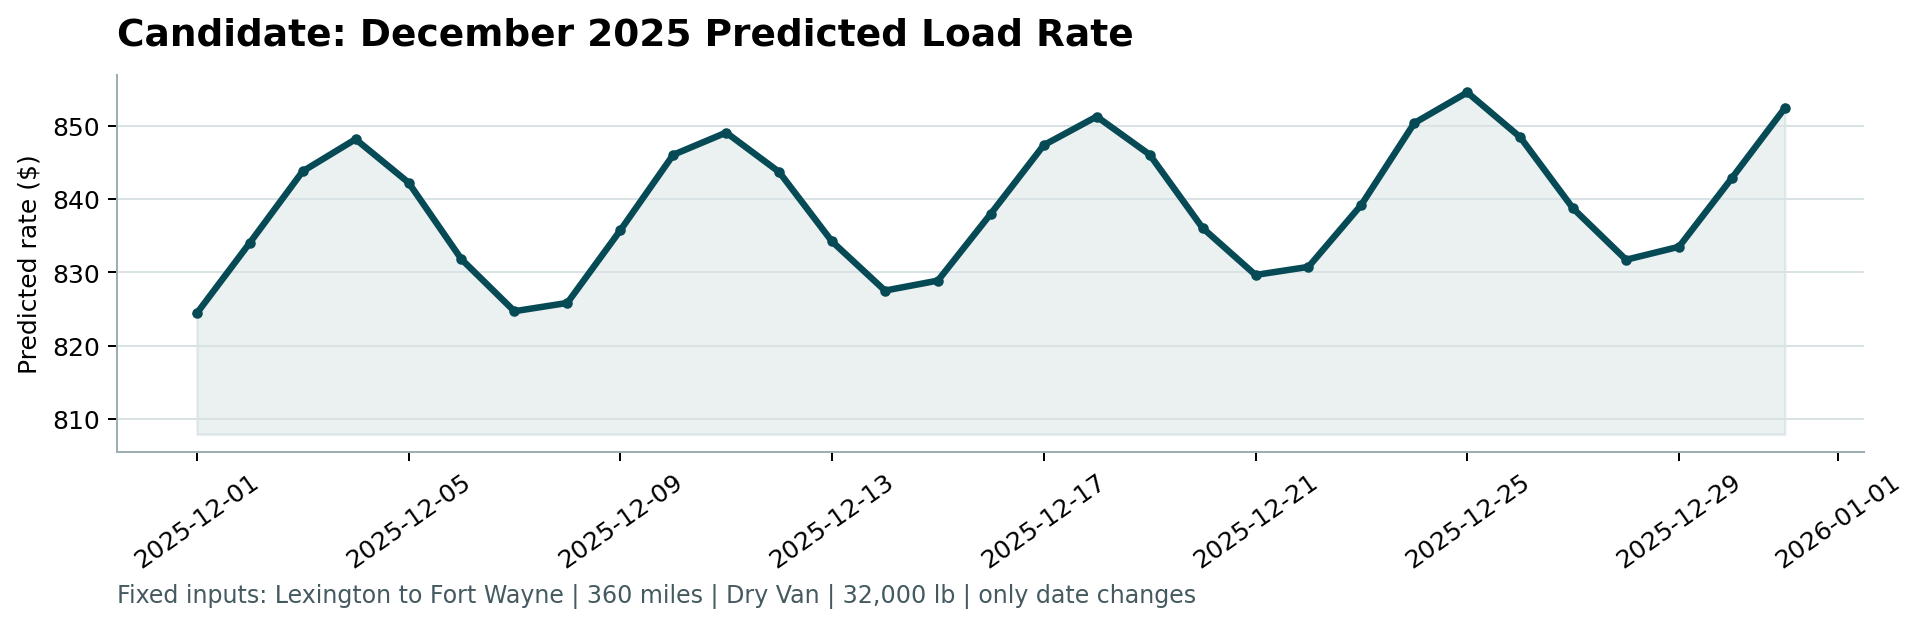

In [ ]:
# ============================================================
# CELL 10 — FINAL PIPELINE
# A. Train model + training-only target cleaning
# B. Generate 12,000 validation predictions
# C. Generate December predictions
# D. Compare December signal strategies
# E. Run official scorer
# ============================================================

import os
import sys
import subprocess
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. FIND REQUIRED FILES
# ------------------------------------------------------------

def find_file(*names):
    for root in ("/content", "/content/data", "."):
        for name in names:
            path = os.path.join(root, name)
            if os.path.isfile(path):
                return os.path.abspath(path)
    return None


TRAIN_PATH = find_file("train-test.csv", "train_test.csv")
VAL_PATH   = find_file("validation.csv")
TMPL_PATH  = find_file(
    "validation-predictions-template.csv",
    "validation_predictions_template.csv"
)
DEC_PATH   = find_file(
    "december-chart-inputs.csv",
    "december_chart_inputs.csv"
)
SCORE_PATH = find_file("score.py")

required_files = {
    "train-test.csv": TRAIN_PATH,
    "validation.csv": VAL_PATH,
    "validation template": TMPL_PATH,
    "December inputs": DEC_PATH,
    "score.py": SCORE_PATH
}

missing = [name for name, path in required_files.items()
           if path is None]

if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

OUTDIR = os.path.dirname(TRAIN_PATH)

print("Files found:")
for name, path in required_files.items():
    print(f"  {name}: {path}")


# ------------------------------------------------------------
# 2. LOAD TRAINING DATA
# ------------------------------------------------------------

train = pd.read_csv(TRAIN_PATH)

required_columns = {
    "pickup", "delivery", "distance", "equipment",
    "weight", "date", "market_index",
    "quote_signal", "posted_rate"
}

assert required_columns.issubset(train.columns), (
    f"Missing training columns: "
    f"{required_columns - set(train.columns)}"
)

train["date"] = pd.to_datetime(
    train["date"], errors="raise"
)

train["weight"] = pd.to_numeric(
    train["weight"], errors="coerce"
).abs()

assert train["posted_rate"].notna().all()
assert (train["posted_rate"] > 0).all()
assert (train["distance"] > 0).all()

T0 = pd.Timestamp("2025-01-01")

MARKET_MED = float(
    pd.to_numeric(
        train["market_index"], errors="coerce"
    ).median()
)

QUOTE_MED = float(
    pd.to_numeric(
        train["quote_signal"], errors="coerce"
    ).median()
)

WEIGHT_MED = float(train["weight"].median())

print("\nTraining shape:", train.shape)
print("Training medians:")
print({
    "market_index": MARKET_MED,
    "quote_signal": QUOTE_MED,
    "weight": WEIGHT_MED
})


# ------------------------------------------------------------
# 3. FEATURE ENGINEERING
# ------------------------------------------------------------

FEATS = [
    "ld", "ld2", "market", "quote",
    "log_w", "is_reefer", "is_flatbed"
]

CITIES = sorted(train["pickup"].dropna().unique().tolist())

K = len(CITIES) - 1
CIDX = {city: i for i, city in enumerate(CITIES)}


def base_frame(data, with_time=True):
    f = pd.DataFrame(index=data.index)

    distance = pd.to_numeric(
        data["distance"], errors="coerce"
    )

    if distance.isna().any() or (distance <= 0).any():
        raise ValueError("Invalid distance values detected.")

    f["ld"] = np.log(distance.astype(float))
    f["ld2"] = f["ld"] ** 2

    if "market_index" in data.columns:
        market = pd.to_numeric(
            data["market_index"], errors="coerce"
        ).fillna(MARKET_MED)
    else:
        market = pd.Series(
            MARKET_MED, index=data.index, dtype=float
        )

    if "quote_signal" in data.columns:
        quote = pd.to_numeric(
            data["quote_signal"], errors="coerce"
        ).fillna(QUOTE_MED)
    else:
        quote = pd.Series(
            QUOTE_MED, index=data.index, dtype=float
        )

    weight = pd.to_numeric(
        data["weight"], errors="coerce"
    ).abs().fillna(WEIGHT_MED)

    if (weight <= 0).any():
        raise ValueError("Non-positive weight after imputation.")

    f["market"] = market
    f["quote"] = quote
    f["log_w"] = np.log(weight)

    f["is_reefer"] = (
        data["equipment"] == "Reefer"
    ).astype(float)

    f["is_flatbed"] = (
        data["equipment"] == "Flatbed"
    ).astype(float)

    if with_time:
        dates = pd.to_datetime(data["date"], errors="raise")
        f["t"] = (dates - T0).dt.days.astype(float)

    return f


def city_block(values):
    matrix = np.zeros((len(values), K))

    for row, city in enumerate(values):
        j = CIDX.get(city)

        if j is None:
            # Unseen city: use the mean of the non-baseline
            # city-effect coefficients.
            matrix[row, :] = 1.0 / K

        elif j > 0:
            matrix[row, j - 1] = 1.0

    return matrix


def design(data, with_time=True):
    features = base_frame(data, with_time)

    blocks = [
        np.ones((len(data), 1)),
        features[
            FEATS + (["t"] if with_time else [])
        ].to_numpy(dtype=float),
        city_block(data["pickup"]),
        city_block(data["delivery"])
    ]

    return np.hstack(blocks)


# ------------------------------------------------------------
# 4. TRAINING-ONLY TARGET CLEANING
# ------------------------------------------------------------

y_log = np.log(
    train["posted_rate"].to_numpy(dtype=float)
)

# Initial model without city effects or time trend.
X_initial = np.hstack([
    np.ones((len(train), 1)),
    base_frame(train, with_time=False)[FEATS].to_numpy(
        dtype=float
    )
])

beta_initial, *_ = np.linalg.lstsq(
    X_initial, y_log, rcond=None
)

residuals = y_log - X_initial @ beta_initial

residual_center = np.median(residuals)

MAD_SIGMA = 1.4826 * np.median(
    np.abs(residuals - residual_center)
)

keep = (
    np.abs(residuals - residual_center)
    < 6 * MAD_SIGMA
)

if keep.sum() == 0:
    raise RuntimeError("No training rows remain after cleaning.")

# Final model trained only on the retained training rows.
X_final = design(train.loc[keep], with_time=True)

coef, *_ = np.linalg.lstsq(
    X_final, y_log[keep], rcond=None
)

print("\nTarget-cleaning summary:")
print(f"Total training rows : {len(train):,}")
print(f"Retained rows       : {int(keep.sum()):,}")
print(f"Flagged rows        : {int((~keep).sum()):,}")
print(f"Flagged percentage  : {(~keep).mean() * 100:.2f}%")
print(f"MAD sigma           : {MAD_SIGMA:.5f}")
print(f"Model coefficients  : {len(coef)}")


# ------------------------------------------------------------
# 5. EXPLICIT SIGNAL IMPUTATION
# ------------------------------------------------------------

def prepare_signals(data, source=None):
    """
    For missing market_index / quote_signal:
      1. Use the median from source rows on the same date.
      2. If unavailable, use the training-data median.

    Existing, non-missing feature values are preserved.
    No target column is used.
    """
    out = data.copy()

    dates = pd.to_datetime(
        out["date"], errors="raise"
    ).dt.normalize()

    signal_medians = {
        "market_index": MARKET_MED,
        "quote_signal": QUOTE_MED
    }

    source_dates = None

    if source is not None and "date" in source.columns:
        source_dates = pd.to_datetime(
            source["date"], errors="coerce"
        ).dt.normalize()

    audit_rows = []

    for col, training_median in signal_medians.items():

        if col in out.columns:
            values = pd.to_numeric(
                out[col], errors="coerce"
            )
        else:
            values = pd.Series(
                np.nan, index=out.index, dtype=float
            )

        initially_missing = int(values.isna().sum())
        filled_by_date = 0

        # Use same-date feature values when available.
        if (
            source is not None
            and source_dates is not None
            and col in source.columns
        ):
            source_values = pd.to_numeric(
                source[col], errors="coerce"
            )

            lookup_frame = pd.DataFrame({
                "_date": source_dates.to_numpy(),
                "_value": source_values.to_numpy()
            })

            daily_median = (
                lookup_frame
                .dropna(subset=["_date", "_value"])
                .groupby("_date")["_value"]
                .median()
            )

            mapped_values = dates.map(daily_median)

            fill_mask = (
                values.isna() & mapped_values.notna()
            )

            filled_by_date = int(fill_mask.sum())

            values.loc[fill_mask] = mapped_values.loc[
                fill_mask
            ]

        # Training-only fallback for anything still missing.
        fallback_mask = values.isna()
        filled_by_training = int(fallback_mask.sum())

        values = values.fillna(training_median)

        if values.isna().any():
            raise ValueError(
                f"Signal imputation failed for {col}"
            )

        out[col] = values.astype(float)

        audit_rows.append({
            "feature": col,
            "initially_missing": initially_missing,
            "filled_from_same_date": filled_by_date,
            "filled_from_training_median": filled_by_training
        })

    return out, pd.DataFrame(audit_rows)


def predict(data, signal_source=None):
    prepared, _ = prepare_signals(
        data, source=signal_source
    )

    log_prediction = design(
        prepared, with_time=True
    ) @ coef

    if not np.isfinite(log_prediction).all():
        raise ValueError("Non-finite model predictions detected.")

    prediction = np.exp(log_prediction)

    if (
        not np.isfinite(prediction).all()
        or (prediction <= 0).any()
    ):
        raise ValueError(
            "Predictions must be finite and positive."
        )

    # No arbitrary rate clipping is applied.
    return prediction


# ------------------------------------------------------------
# 6. VALIDATION PREDICTIONS — 12,000 ROWS
# ------------------------------------------------------------

val = pd.read_csv(VAL_PATH)
template = pd.read_csv(TMPL_PATH)

assert len(val) == 12000, (
    f"Expected 12,000 validation rows, got {len(val)}"
)

assert "load_id" in val.columns
assert "load_id" in template.columns

assert val["load_id"].notna().all()
assert template["load_id"].notna().all()

assert val["load_id"].is_unique
assert template["load_id"].is_unique

if set(val["load_id"]) != set(template["load_id"]):
    raise ValueError(
        "Validation IDs do not match template IDs."
    )

# Existing signals are preserved. Missing signals, if any,
# use same-date validation features, then training medians.
pred_val = np.round(
    predict(val, signal_source=val), 2
)

prediction_frame = pd.DataFrame({
    "load_id": val["load_id"],
    "predicted_rate": pred_val
})

validation_output = template[["load_id"]].merge(
    prediction_frame,
    on="load_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert len(validation_output) == 12000
assert validation_output["predicted_rate"].notna().all()
assert (validation_output["predicted_rate"] > 0).all()

VAL_OUTPUT_PATH = os.path.join(
    OUTDIR, "validation_predictions.csv"
)

validation_output.to_csv(
    VAL_OUTPUT_PATH, index=False
)

print("\nValidation predictions:")
print("Rows :", len(validation_output))
print("Mean :", round(validation_output["predicted_rate"].mean(), 2))
print("Min  :", round(validation_output["predicted_rate"].min(), 2))
print("Max  :", round(validation_output["predicted_rate"].max(), 2))
print("Saved:", VAL_OUTPUT_PATH)


# ------------------------------------------------------------
# 7. DECEMBER PREDICTIONS + SENSITIVITY CHECK
# ------------------------------------------------------------

dec = pd.read_csv(DEC_PATH)

expected_dec_columns = [
    "pickup", "delivery", "distance",
    "equipment", "weight", "date", "predicted_rate"
]

if list(dec.columns) != expected_dec_columns:
    raise ValueError(
        "Unexpected December input columns/order: "
        f"{list(dec.columns)}"
    )

assert len(dec) == 31

# Strategy A:
# Fill missing daily market/quote features from validation
# rows on the matching date; fallback to training medians.
_, imputation_audit = prepare_signals(
    dec, source=val
)

pred_dec_same_date = np.round(
    predict(dec, signal_source=val), 2
)

# Strategy B:
# Sensitivity analysis — use training medians for all
# December market/quote signals.
dec_fallback = dec.copy()
dec_fallback["market_index"] = MARKET_MED
dec_fallback["quote_signal"] = QUOTE_MED

pred_dec_training_medians = np.round(
    predict(dec_fallback), 2
)

print("\nDecember signal-imputation audit:")
print(imputation_audit.to_string(index=False))

sensitivity = pd.DataFrame({
    "date": dec["date"],
    "predicted_rate_same_date_signals": pred_dec_same_date,
    "predicted_rate_training_medians": pred_dec_training_medians
})

sensitivity["absolute_difference"] = (
    sensitivity["predicted_rate_same_date_signals"]
    - sensitivity["predicted_rate_training_medians"]
).abs()

sensitivity["pct_difference_vs_training_median"] = (
    (
        sensitivity["predicted_rate_same_date_signals"]
        / sensitivity["predicted_rate_training_medians"]
    ) - 1
) * 100

SENSITIVITY_PATH = os.path.join(
    OUTDIR, "december_signal_sensitivity.csv"
)

sensitivity.to_csv(SENSITIVITY_PATH, index=False)

print("\nDecember sensitivity check:")
print(
    "Mean absolute difference: $"
    f"{sensitivity['absolute_difference'].mean():.2f}"
)
print(
    "Maximum absolute difference: $"
    f"{sensitivity['absolute_difference'].max():.2f}"
)
print(
    "Mean absolute percentage difference: "
    f"{sensitivity['pct_difference_vs_training_median'].abs().mean():.3f}%"
)

# Use Strategy A for the primary submission chart.
dec_filled = dec.copy()
dec_filled["predicted_rate"] = pred_dec_same_date

DEC_OUTPUT_PATH = os.path.join(
    OUTDIR, "december-chart-inputs-filled.csv"
)

dec_filled.to_csv(DEC_OUTPUT_PATH, index=False)

print("\nDecember predictions:")
print("Rows :", len(dec_filled))
print("Min  :", round(dec_filled["predicted_rate"].min(), 2))
print("Max  :", round(dec_filled["predicted_rate"].max(), 2))
print("Mean :", round(dec_filled["predicted_rate"].mean(), 2))
print("Saved:", DEC_OUTPUT_PATH)

print("Saved sensitivity table:", SENSITIVITY_PATH)


# ------------------------------------------------------------
# 8. RUN OFFICIAL SCORER
# ------------------------------------------------------------

run = subprocess.run(
    [
        sys.executable,
        SCORE_PATH,
        "--predictions", VAL_OUTPUT_PATH,
        "--december-predictions", DEC_OUTPUT_PATH
    ],
    capture_output=True,
    text=True,
    cwd=OUTDIR
)

print("\nOfficial scorer output:")
print(run.stdout)

if run.returncode != 0:
    print("SCORER STDERR:")
    print(run.stderr)
    raise RuntimeError(
        f"Official scorer failed with code {run.returncode}"
    )

CHART_PATH = os.path.join(
    OUTDIR, "scorer_results", "candidate_december.png"
)

if not os.path.isfile(CHART_PATH):
    raise FileNotFoundError(
        f"Scorer did not create expected chart: {CHART_PATH}"
    )

print("\nSUCCESS")
print("Validation file:", VAL_OUTPUT_PATH)
print("December file  :", DEC_OUTPUT_PATH)
print("Sensitivity    :", SENSITIVITY_PATH)
print("Chart          :", CHART_PATH)

from IPython.display import Image, display
display(Image(filename=CHART_PATH, width=980))

Inputs: /content/train-test.csv /content/validation.csv /content/december-chart-inputs.csv | saved prediction CSV: /content/validation_predictions.csv | filled December CSV: /content/december-chart-inputs-filled.csv | official chart: /content/scorer_results/candidate_december.png
Rows: 48000 train; 12000 validation; 31 December chart inputs
Dates: 2025-01-01 → 2025-10-31 ; validation: 2025-11-01 → 2025-12-31

PAGE 1 — dataset / quality / geography / target
Train-only 6×MAD-sigma threshold: 0.23738 | retained: 47323 | flagged: 677
Missing (%): {'weight': 0.625, 'market_index': 0.779}
Negative weights: 292 | exact duplicate rows: 0
Unique cities: 64 | validation new cities: 8


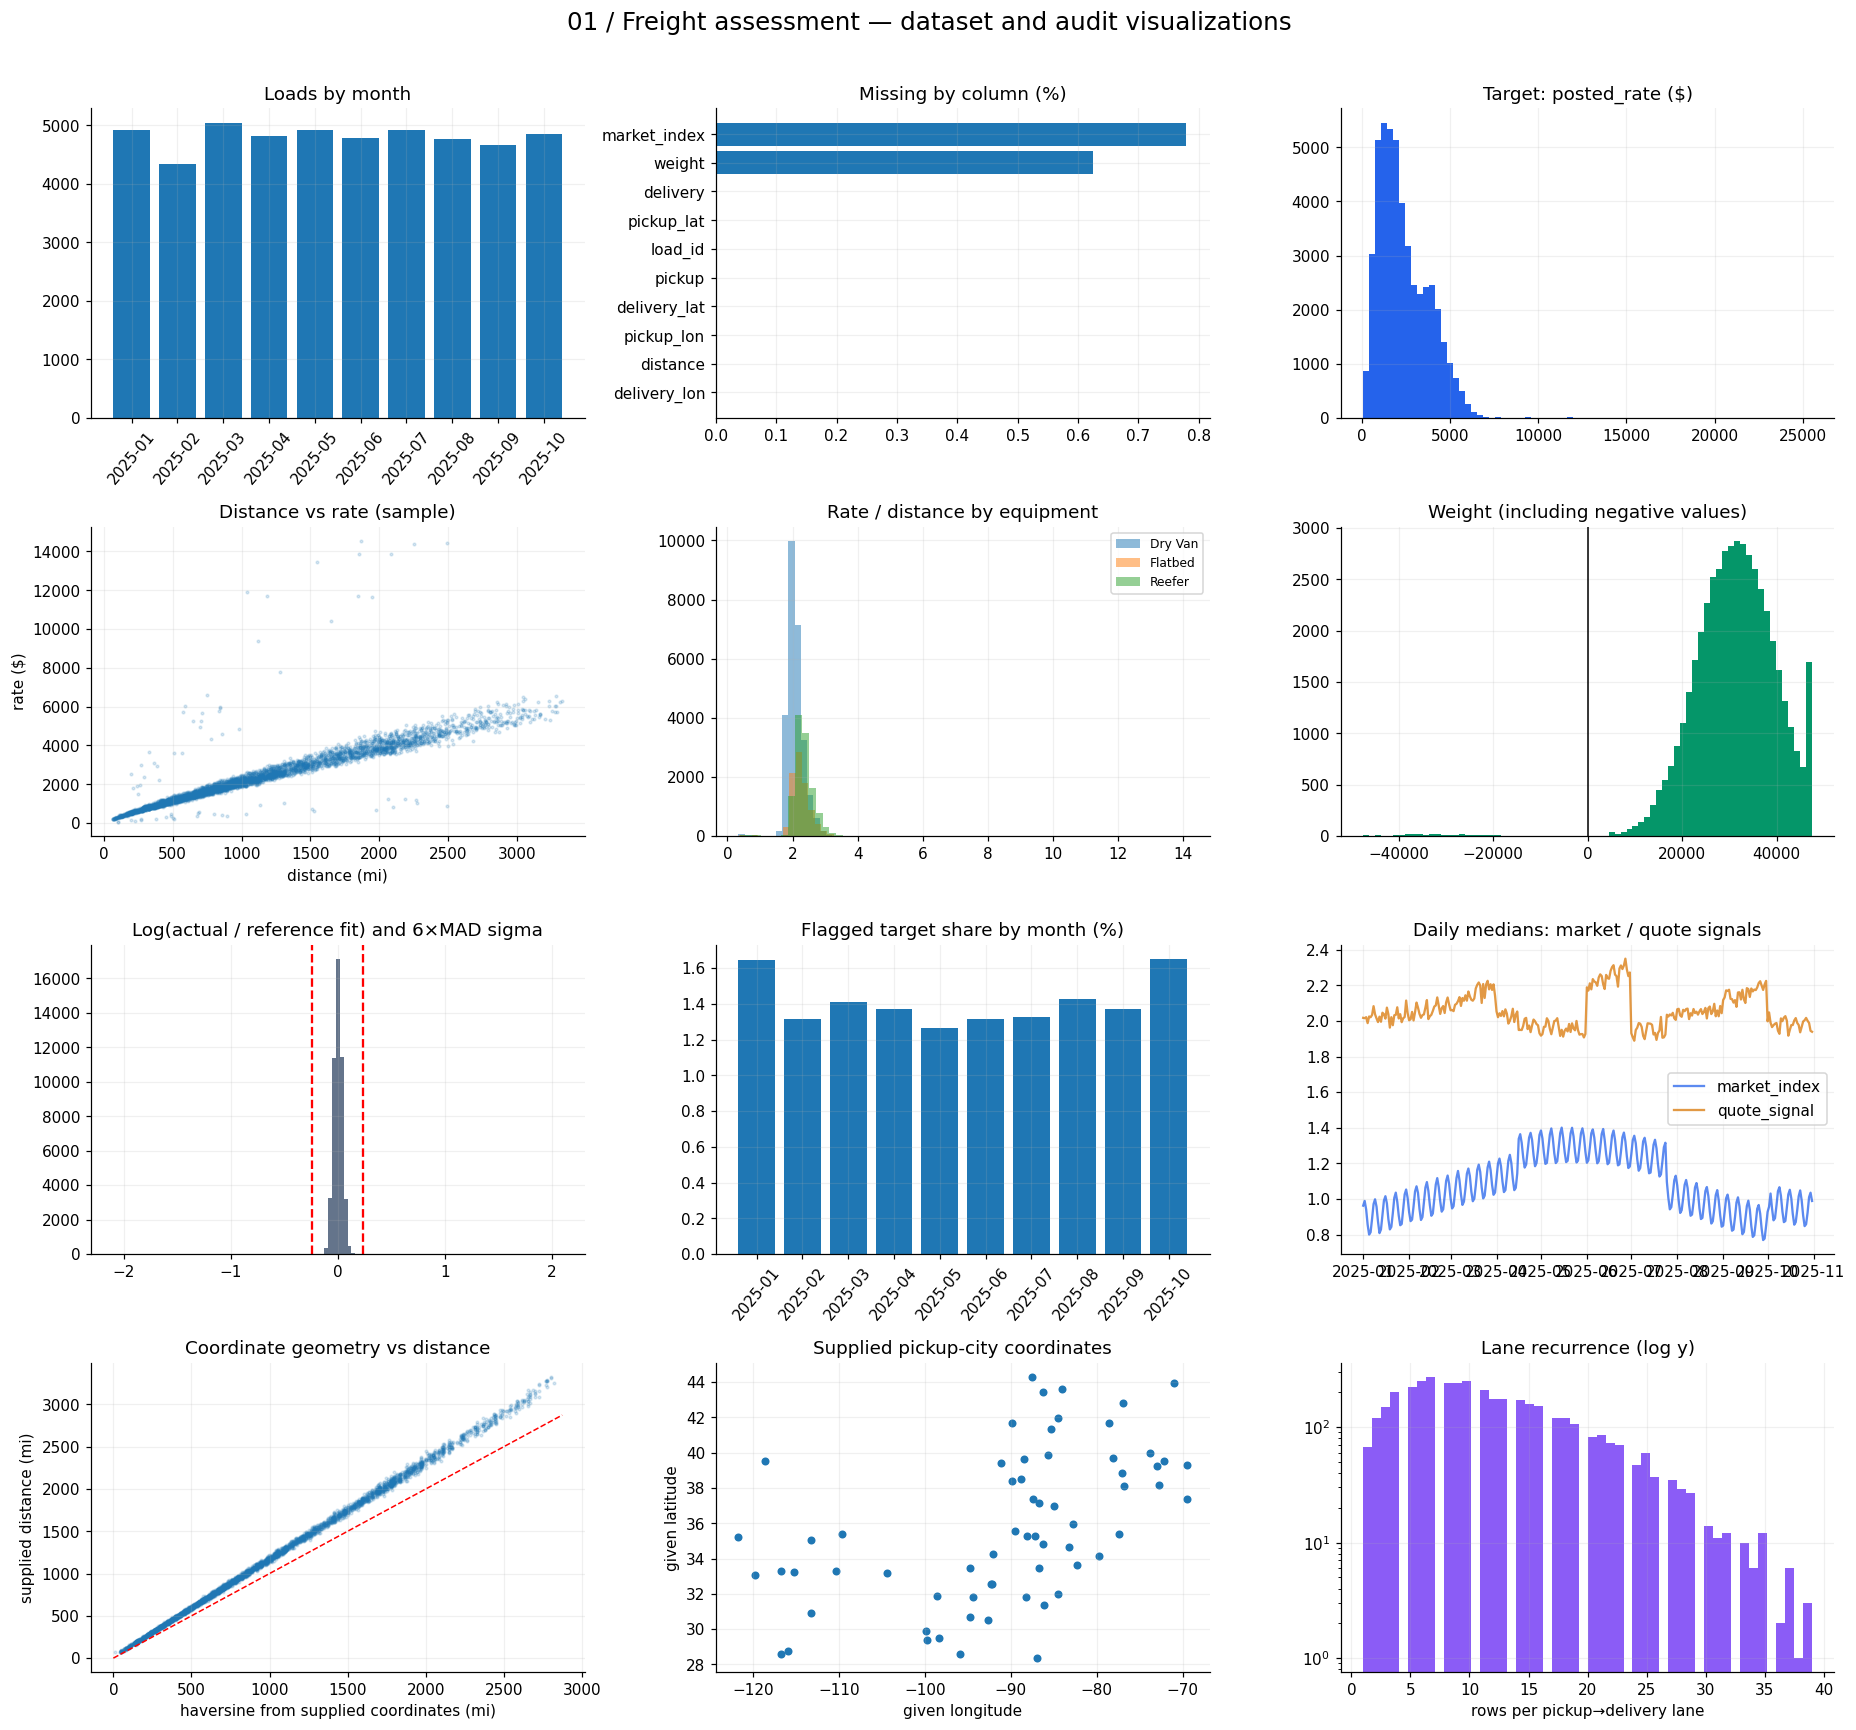

Saved: /content/freight_visuals/01_data_quality.png

PAGE 2 — validation protocols and model comparison
Shipped pipeline, Jan–Aug → Sep–Oct holdout:
            group    n      MAE   MAPE     R2
clean scored rows 9379  48.3021 2.0764 0.9971
  ALL scored rows 9523 104.2670 4.5838 0.8281
GBM fit without time 16.9s
GBM fit with time 17.3s
Fixed-mask family audit (models trained without filtering; distinct from shipped model):
         model  MAE_clean   MAE_all  R2_all
          mean  1110.5074 1152.0629 -0.0869
      distance   134.0095  188.6237  0.8152
linear no time   103.4522  158.6137  0.8196
   GBM no time    94.0149  149.2599  0.8210
 linear + time    49.7964  105.7065  0.8283
    GBM + time    95.5594  150.6449  0.8217


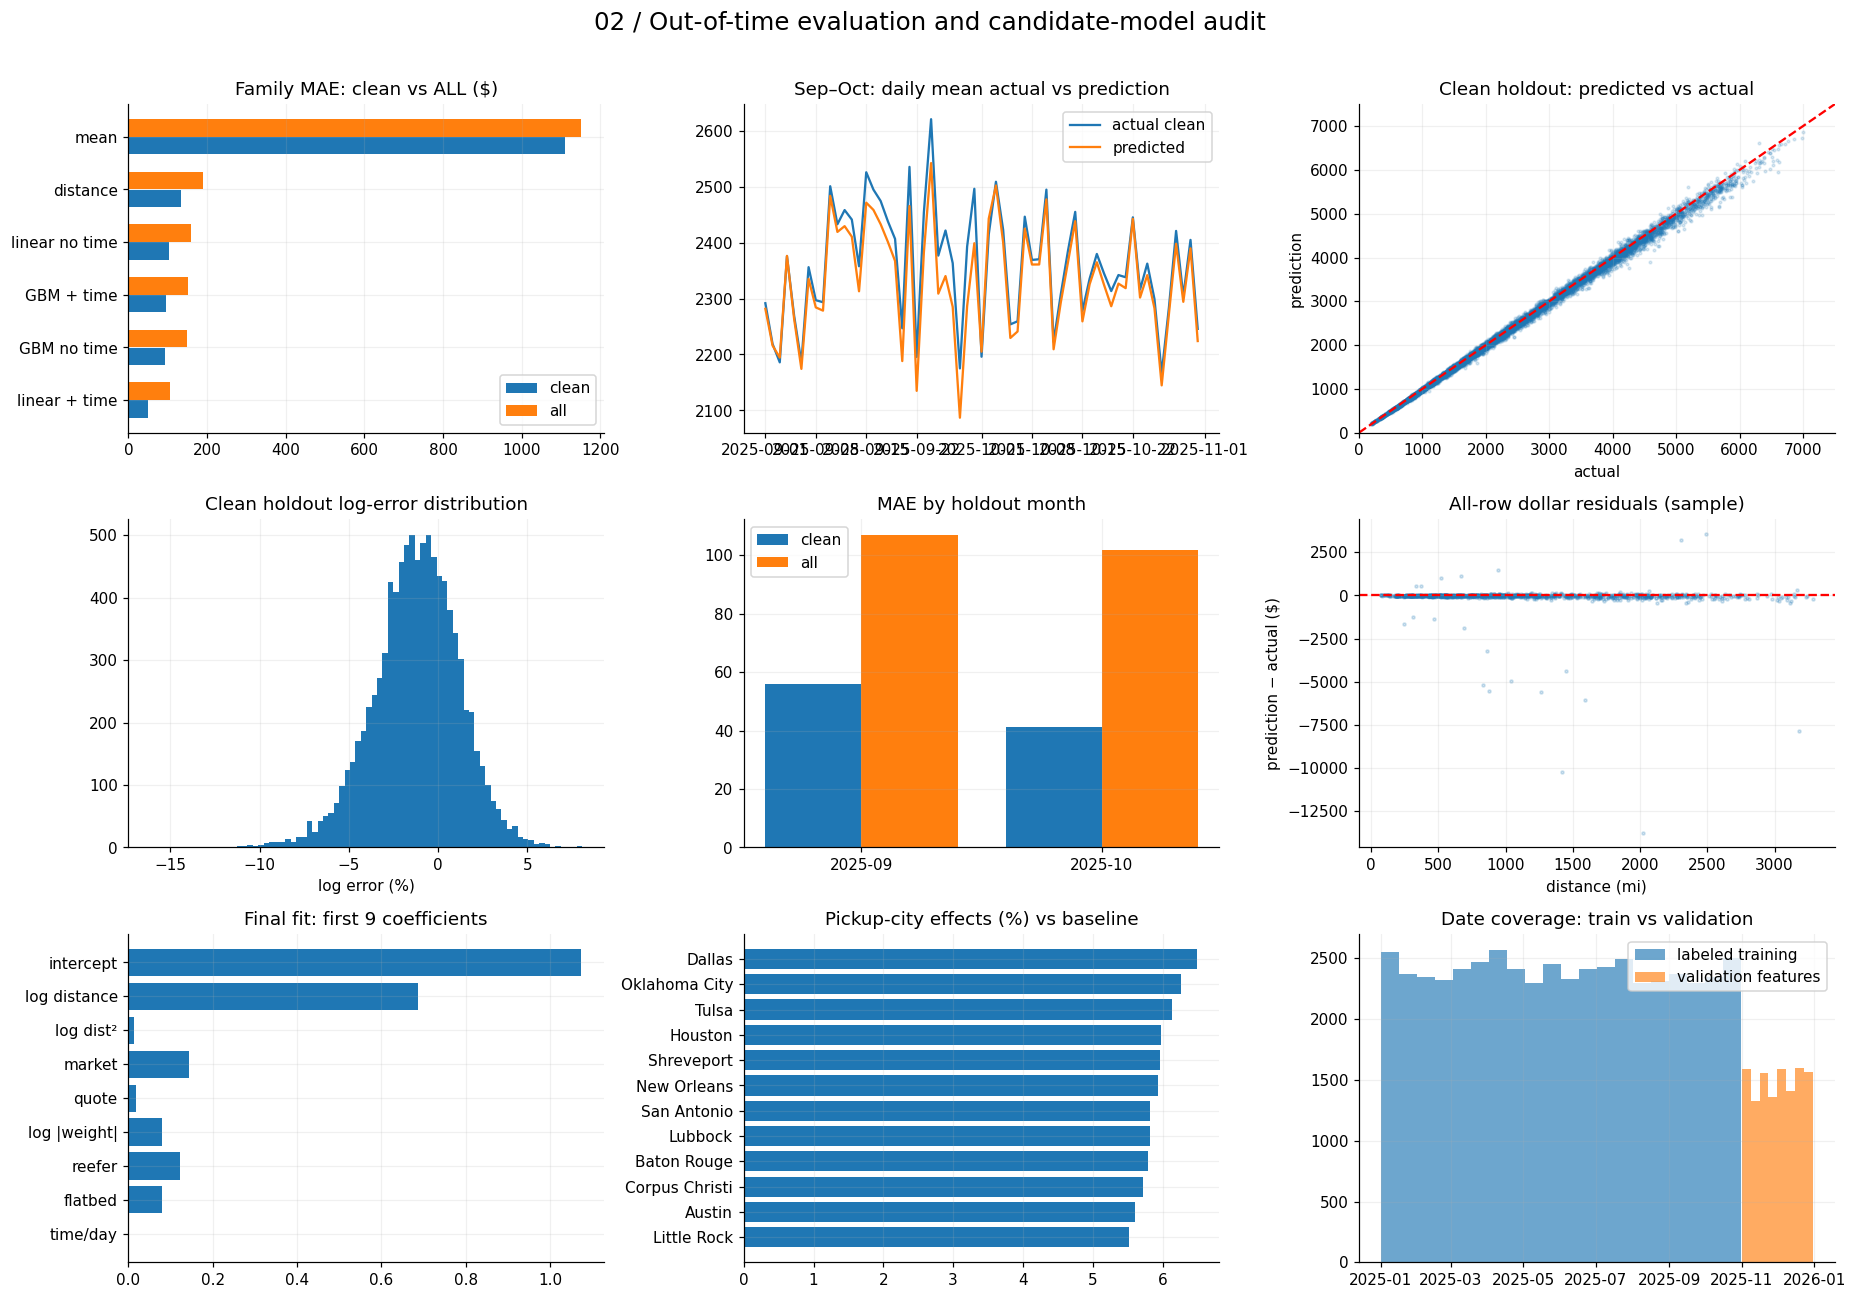

Saved: /content/freight_visuals/02_validation_models.png

PAGE 3 — final output and December feature-availability sensitivity
Validation saved-file rows: 12000 | missing matching IDs: 0 | max abs difference: 170.11000000000058
December saved-file rows: 31 | max abs difference: 0.0
December signal-source comparison:
same-date supplied validation FEATURES | mean 839.05 | range 824.42 to 854.51 | peak 2025-12-25
training medians only | mean 853.91 | range 851.19 to 856.65 | peak 2025-12-31
Same-date minus training-median: mean $ -14.86 | max abs $ 27.57


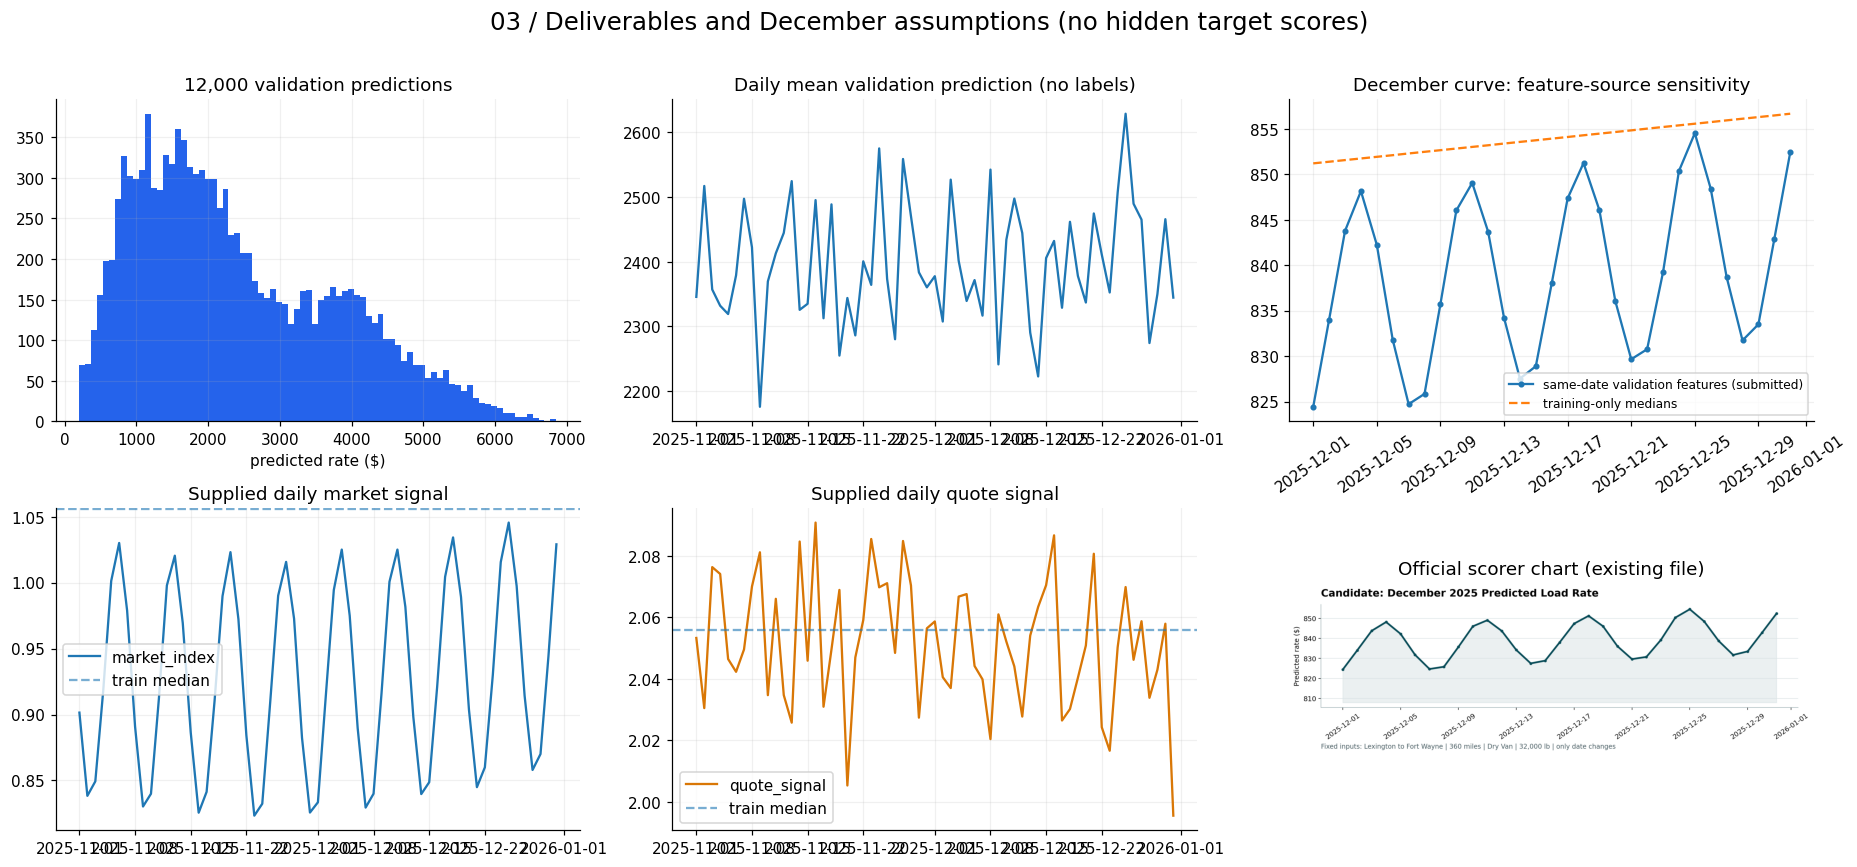

Saved: /content/freight_visuals/03_predictions_december.png

PAGE 4 — rolling forecast windows / city & lane deployment checks
7-fold clean MAE by time handling (measured, not a selected verdict):
mode     anchor-only  linear  linear+anchor   none
fold                                              
Mar–Apr        140.9   138.6          138.5  141.6
Apr–May        264.8   248.3          248.5  264.4
May–Jun         65.5    51.1           52.5   65.6
Jun–Jul         66.5    56.3           56.3   69.9
Jul–Aug         47.3   106.7          115.7   56.9
Aug–Sep         74.4    55.8           49.3   93.3
Sep–Oct         71.7    49.8           56.4  103.5
Unweighted 7-fold mean: {'anchor-only': 104.4, 'linear': 100.9, 'linear+anchor': 102.5, 'none': 113.6}
Unseen validation cities and affected load counts: {'Knoxville': 170, 'Allentown': 171, 'Norfolk': 172, 'Charlotte': 176, 'Chicago': 179, 'San Diego': 191, 'Jackson': 193, 'Laredo': 195}
Repeated-lane distance CV median: 0.017617511820450585

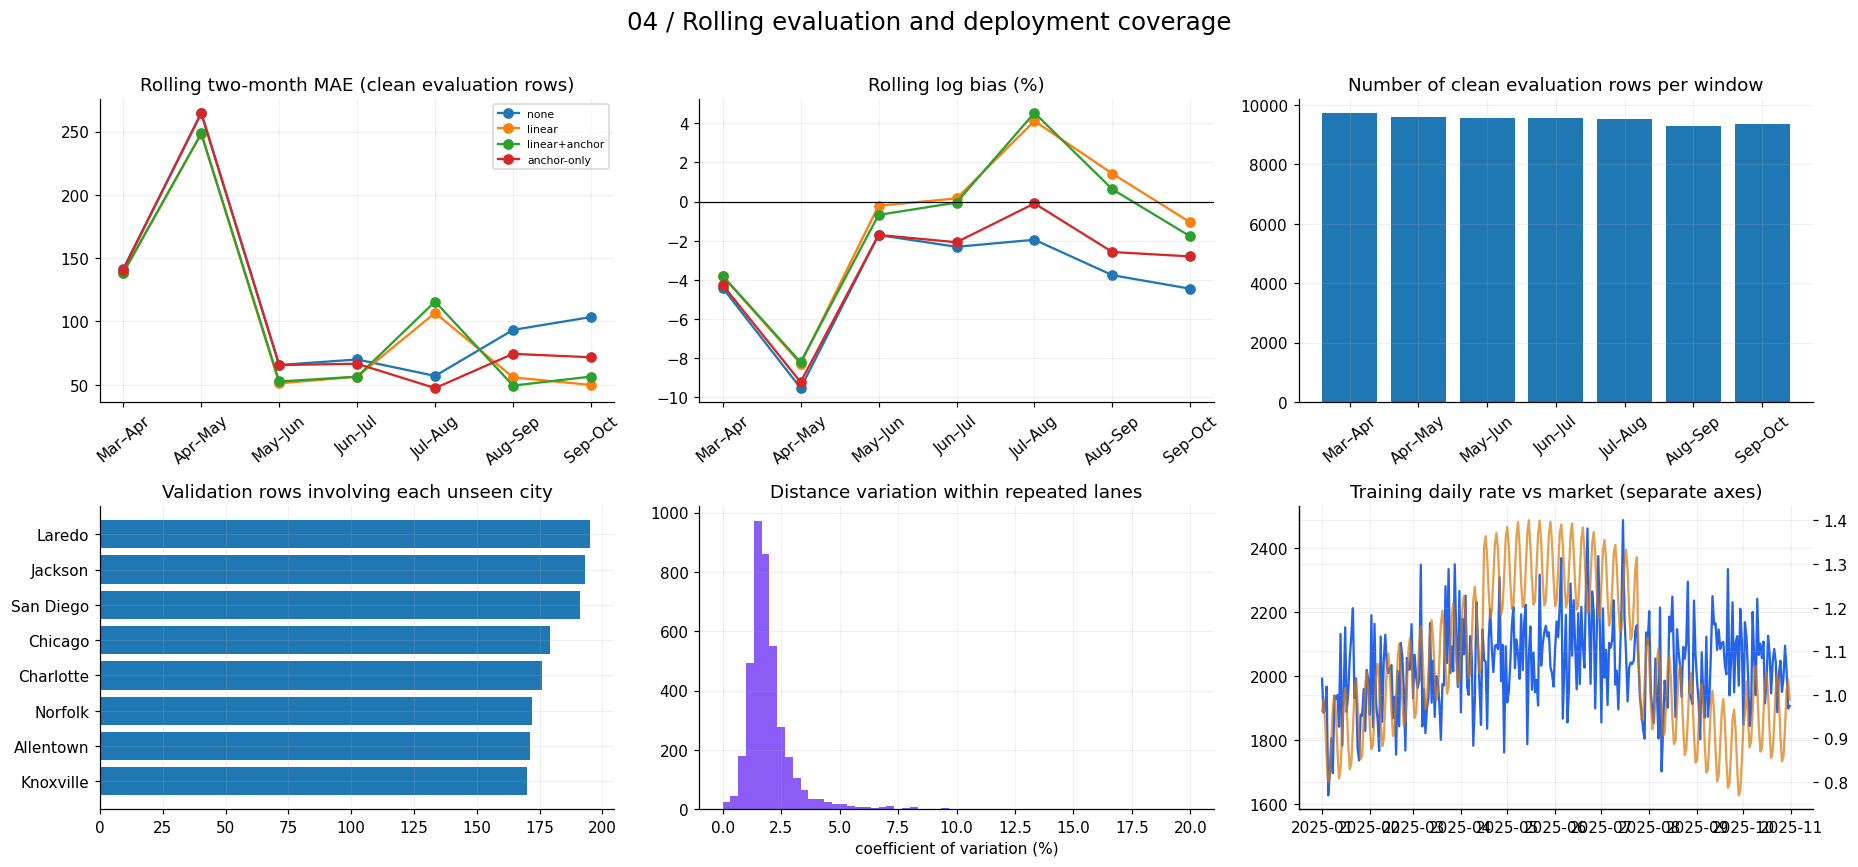

Saved: /content/freight_visuals/04_rolling_city_lane.png

DONE. PNG dashboards: ['/content/freight_visuals/01_data_quality.png', '/content/freight_visuals/02_validation_models.png', '/content/freight_visuals/03_predictions_december.png', '/content/freight_visuals/04_rolling_city_lane.png']
All original/submitted CSVs were read, NOT modified. These charts do not test hidden accuracy.


In [ ]:
# FREIGHT ASSESSMENT — ONE-CELL VISUAL DASHBOARD
# Read-only for all supplied/submitted CSVs. Saves dashboard PNGs to freight_visuals/.
# Requires: numpy, pandas, matplotlib, scikit-learn (preinstalled in most Colab runtimes).
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from IPython.display import display, Image

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .18,
                     "axes.spines.top": False, "axes.spines.right": False})
ROOTS = [Path('/content'), Path('/content/data'), Path('.'), Path('data')]
SIGNATURE = {'load_id','pickup','delivery','distance','equipment','weight','date',
             'market_index','quote_signal','posted_rate'}

def locate(names, required=(), optional=False):
    for root in ROOTS:
        for name in names:
            p = root/name
            if p.is_file():
                if not required or required.issubset(set(pd.read_csv(p, nrows=0).columns)):
                    return p
    if optional:
        return None
    raise FileNotFoundError(f'No matching freight CSV: {names} (required columns: {required})')

TRAIN = locate(['train-test.csv','train_test.csv'], SIGNATURE)
VAL = locate(['validation.csv'], SIGNATURE-{'posted_rate'})
DEC = locate(['december-chart-inputs.csv','december_chart_inputs.csv'],
             {'pickup','delivery','distance','equipment','weight','date'})
PRED = locate(['validation_predictions.csv','outputs/validation_predictions.csv'],
              {'load_id','predicted_rate'}, optional=True)
DEC_PRED = locate(['december-chart-inputs-filled.csv','outputs/december-chart-inputs.csv'],
                  {'date','predicted_rate'}, optional=True)
CHART = next((p for root in ROOTS for p in
              [root/'scorer_results/candidate_december.png',root/'reports/candidate_december.png']
              if p.is_file()), None)
OUT = Path('/content/freight_visuals') if Path('/content').exists() else Path('freight_visuals')
OUT.mkdir(parents=True, exist_ok=True)
d = pd.read_csv(TRAIN, parse_dates=['date'])
v = pd.read_csv(VAL, parse_dates=['date'])
dec = pd.read_csv(DEC, parse_dates=['date'])
assert len(d) and len(v) and len(dec) and (d.posted_rate > 0).all() and (d.distance > 0).all()
print('Inputs:', TRAIN, VAL, DEC, '| saved prediction CSV:', PRED,
      '| filled December CSV:', DEC_PRED, '| official chart:', CHART)
print('Rows:',len(d),'train;',len(v),'validation;',len(dec),'December chart inputs')
print('Dates:',d.date.min().date(),'→',d.date.max().date(),'; validation:',v.date.min().date(),'→',v.date.max().date())

# Feature matrix + the SAME train-only 6×MAD-sigma cleaning / log-linear model as Cell 10.
T0 = pd.Timestamp('2025-01-01')
def meds(x):
    return {'market': float(x.market_index.median()),
            'quote': float(x.quote_signal.median()),
            'weight': float(pd.to_numeric(x.weight, errors='coerce').abs().median())}
def X(x, m, cities, with_time=True):
    ld = np.log(pd.to_numeric(x.distance).to_numpy(float))
    market = (pd.to_numeric(x.market_index,errors='coerce').fillna(m['market']).to_numpy(float)
              if 'market_index' in x else np.full(len(x),m['market']))
    quote = (pd.to_numeric(x.quote_signal,errors='coerce').fillna(m['quote']).to_numpy(float)
             if 'quote_signal' in x else np.full(len(x),m['quote']))
    weight = np.log(pd.to_numeric(x.weight,errors='coerce').abs().fillna(m['weight']).to_numpy(float))
    parts = [np.ones((len(x),1)), np.column_stack([ld,ld**2,market,quote,weight,
             (x.equipment=='Reefer').to_numpy(float),(x.equipment=='Flatbed').to_numpy(float)])]
    if with_time:
        parts.append(((pd.to_datetime(x.date)-T0).dt.days.to_numpy(float))[:,None])
    k = len(cities)-1; idx = {c:i for i,c in enumerate(cities)}
    for col in ['pickup','delivery']:
        block = np.zeros((len(x),k))
        for row,city in enumerate(x[col].to_numpy()):
            j = idx.get(city)
            if j is None: block[row,:] = 1/k  # unseen city -> mean fitted city effect
            elif j>0: block[row,j-1] = 1
        parts.append(block)
    return np.hstack(parts)
def fit(train):
    m=meds(train); cities=sorted(train.pickup.unique().tolist())
    base=X(train,m,cities,False)[:,:8] # intercept + 7 non-time continuous features
    y=np.log(train.posted_rate.to_numpy(float))
    b0=np.linalg.lstsq(base,y,rcond=None)[0]; resid=y-base@b0
    mad_sigma=1.4826*np.median(np.abs(resid-np.median(resid)))
    keep=np.abs(resid-np.median(resid)) < 6*mad_sigma
    coef=np.linalg.lstsq(X(train.loc[keep],m,cities),y[keep],rcond=None)[0]
    return {'m':m,'cities':cities,'coef':coef,'keep':keep,'sigma':mad_sigma,'ref_resid':resid}
def predict(model,x,source=None):
    x=x.copy()
    if source is not None and ('market_index' not in x or 'quote_signal' not in x):
        by_day=source.assign(_day=pd.to_datetime(source.date)).groupby('_day')[
            ['market_index','quote_signal']].median()
        days=pd.to_datetime(x.date)
        for col in ['market_index','quote_signal']:
            if col not in x: x[col]=days.map(by_day[col]).to_numpy()
    return np.clip(np.exp(X(x,model['m'],model['cities'])@model['coef']),25,40000)
def stats(y,p,mask):
    y=np.asarray(y)[mask];p=np.asarray(p)[mask]
    return {'n':len(y),'MAE':np.mean(np.abs(y-p)),
            'MAPE':100*np.mean(np.abs(y-p)/y),
            'R2':1-np.sum((y-p)**2)/np.sum((y-y.mean())**2)}
def finish(fig,name):
    fig.tight_layout(rect=(0,0,1,.97)); fig.savefig(OUT/name,bbox_inches='tight',dpi=140)
    plt.show();plt.close(fig);print('Saved:',OUT/name)

# ────────────────────────────────────────────────────────────────────────────
# PAGE 1 — INPUT DATA, QUALITY, GEOMETRY, TARGET STRUCTURE
# ────────────────────────────────────────────────────────────────────────────
print('\nPAGE 1 — dataset / quality / geography / target')
full=fit(d); mult=np.exp(full['ref_resid']); flagged=~full['keep']
print('Train-only 6×MAD-sigma threshold:',round(6*full['sigma'],5),
      '| retained:',int(full['keep'].sum()),'| flagged:',int(flagged.sum()))
print('Missing (%):', (100*d.isna().mean()).loc[lambda s:s>0].round(3).to_dict())
print('Negative weights:',int((d.weight<0).sum()),'| exact duplicate rows:',int(d.duplicated().sum()))
print('Unique cities:',len(set(d.pickup)|set(d.delivery)),
      '| validation new cities:',len((set(v.pickup)|set(v.delivery))-(set(d.pickup)|set(d.delivery))))
fig,ax=plt.subplots(4,3,figsize=(17,16)); a=ax.ravel()
monthly=d.groupby(d.date.dt.to_period('M')).size();a[0].bar(monthly.index.astype(str),monthly)
a[0].tick_params(axis='x',rotation=50);a[0].set_title('Loads by month')
miss=(100*d.isna().mean()).sort_values(ascending=False).head(10);a[1].barh(miss.index[::-1],miss.values[::-1]);a[1].set_title('Missing by column (%)')
a[2].hist(d.posted_rate,bins=75,color='#2563eb');a[2].set_title('Target: posted_rate ($)')
samp=d.sample(min(len(d),4500),random_state=4)
a[3].scatter(samp.distance,samp.posted_rate,s=3,alpha=.17);a[3].set(xlabel='distance (mi)',ylabel='rate ($)',title='Distance vs rate (sample)')
for eq,g in d.groupby('equipment'):
    a[4].hist((g.posted_rate/g.distance).clip(0,20),bins=65,alpha=.5,label=eq)
a[4].legend(fontsize=8);a[4].set_title('Rate / distance by equipment')
a[5].hist(d.weight.dropna(),bins=75,color='#059669');a[5].axvline(0,c='black',lw=1);a[5].set_title('Weight (including negative values)')
a[6].hist(np.log(mult),bins=115,range=(-2.1,2.1),color='#64748b')
a[6].axvline(-6*full['sigma'],c='red',ls='--');a[6].axvline(6*full['sigma'],c='red',ls='--')
a[6].set_title('Log(actual / reference fit) and 6×MAD sigma')
tmp=pd.DataFrame({'month':d.date.dt.to_period('M').astype(str),'flag':flagged})
fshare=100*tmp.groupby('month').flag.mean();a[7].bar(fshare.index,fshare)
a[7].tick_params(axis='x',rotation=50);a[7].set_title('Flagged target share by month (%)')
for col,color in [('market_index','#2563eb'),('quote_signal','#d97706')]:
    daily=d.groupby('date')[col].median();a[8].plot(daily.index,daily,color=color,label=col,alpha=.75)
a[8].legend();a[8].set_title('Daily medians: market / quote signals')
rad=np.pi/180;la1=d.pickup_lat*rad;la2=d.delivery_lat*rad;dlon=(d.delivery_lon-d.pickup_lon)*rad
h=2*3958.8*np.arcsin(np.sqrt(np.clip(np.sin((la2-la1)/2)**2+
     np.cos(la1)*np.cos(la2)*np.sin(dlon/2)**2,0,1)))
a[9].scatter(h.iloc[samp.index],d.distance.iloc[samp.index],s=3,alpha=.17)
a[9].plot([0,h.max()],[0,h.max()],ls='--',c='red',lw=1)
a[9].set(xlabel='haversine from supplied coordinates (mi)',ylabel='supplied distance (mi)',
         title='Coordinate geometry vs distance')
city_geo=d[['pickup','pickup_lat','pickup_lon']].drop_duplicates('pickup')
a[10].scatter(city_geo.pickup_lon,city_geo.pickup_lat,s=18)
a[10].set(xlabel='given longitude',ylabel='given latitude',title='Supplied pickup-city coordinates')
lanes=d.groupby(['pickup','delivery']).size()
a[11].hist(lanes,bins=50,color='#8b5cf6');a[11].set_yscale('log')
a[11].set(xlabel='rows per pickup→delivery lane',title='Lane recurrence (log y)')
fig.suptitle('01 / Freight assessment — dataset and audit visualizations',fontsize=16)
finish(fig,'01_data_quality.png')

# ────────────────────────────────────────────────────────────────────────────
# PAGE 2 — TEMPORAL HOLDOUT + MODEL FAMILIES (SAME COMPARISON SETTINGS AS AUDIT)
# ────────────────────────────────────────────────────────────────────────────
print('\nPAGE 2 — validation protocols and model comparison')
tr=d[d.date<'2025-09-01'];te=d[d.date>='2025-09-01']
held=fit(tr);pred=predict(held,te);y=te.posted_rate.to_numpy(float)
clean_mask=np.abs(np.log(y)-np.log(pred))<.4 # labels used ONLY to report clean/all scores
score_rows=[]
for label,mask in [('clean scored rows',clean_mask),('ALL scored rows',np.ones(len(te),bool))]:
    score_rows.append({'group':label,**stats(y,pred,mask)})
print('Shipped pipeline, Jan–Aug → Sep–Oct holdout:')
print(pd.DataFrame(score_rows).round(4).to_string(index=False))

# Fixed clean mask for FAMILY reporting, independent of any compared family.
# This reproduces the Cell-9 distance-only full-dataset diagnostic; no holdout data is fit
# into any compared model (only the evaluation mask uses observed holdout labels).
ld_all=np.log(d.distance.to_numpy(float));yy=np.log(d.posted_rate.to_numpy(float))
bd=np.linalg.lstsq(np.column_stack([np.ones(len(d)),ld_all]),yy,rcond=None)[0]
mask_family=(np.abs(yy-np.column_stack([np.ones(len(d)),ld_all])@bd)<.4)[d.date>='2025-09-01']
m=meds(tr);cities=sorted(tr.pickup.unique().tolist()); logy=np.log(tr.posted_rate.to_numpy(float))
family={}
family['mean']=np.full(len(te),np.exp(logy.mean()))
B=np.linalg.lstsq(np.column_stack([np.ones(len(tr)),np.log(tr.distance)]),logy,rcond=None)[0]
family['distance']=np.exp(np.column_stack([np.ones(len(te)),np.log(te.distance)])@B)
for with_time in [False,True]:
    xtr=X(tr,m,cities,with_time);xte=X(te,m,cities,with_time)
    b=np.linalg.lstsq(xtr,logy,rcond=None)[0]
    family['linear + time' if with_time else 'linear no time']=np.exp(xte@b)
    t=time.time();gbm=HistGradientBoostingRegressor(max_iter=300,learning_rate=.08,
              max_leaf_nodes=63,early_stopping=False,random_state=0)
    gbm.fit(xtr,logy)
    family['GBM + time' if with_time else 'GBM no time']=np.exp(gbm.predict(xte))
    print('GBM fit',('with time' if with_time else 'without time'),f'{time.time()-t:.1f}s')
family_df=pd.DataFrame([{'model':name,'MAE_clean':stats(y,p,mask_family)['MAE'],
                         'MAE_all':stats(y,p,np.ones(len(y),bool))['MAE'],
                         'R2_all':stats(y,p,np.ones(len(y),bool))['R2']}
                        for name,p in family.items()])
print('Fixed-mask family audit (models trained without filtering; distinct from shipped model):')
print(family_df.round(4).to_string(index=False))
fig,ax=plt.subplots(3,3,figsize=(17,12));a=ax.ravel()
q=family_df.sort_values('MAE_clean');inds=np.arange(len(q))
a[0].barh(inds-.17,q.MAE_clean,height=.33,label='clean');a[0].barh(inds+.17,q.MAE_all,height=.33,label='all')
a[0].set_yticks(inds,q.model);a[0].legend();a[0].set_title('Family MAE: clean vs ALL ($)')
res=pd.DataFrame({'date':te.date.values,'actual':y,'pred':pred})
g=res[clean_mask].groupby('date')[['actual','pred']].mean()
a[1].plot(g.index,g.actual,label='actual clean');a[1].plot(g.index,g.pred,label='predicted')
a[1].legend();a[1].set_title('Sep–Oct: daily mean actual vs prediction')
a[2].scatter(y[clean_mask],pred[clean_mask],s=3,alpha=.16)
a[2].plot([0,y.max()],[0,y.max()],c='red',ls='--');a[2].set(xlabel='actual',ylabel='prediction',
      xlim=(0,7500),ylim=(0,7500),title='Clean holdout: predicted vs actual')
a[3].hist(100*np.log(pred[clean_mask]/y[clean_mask]),bins=80)
a[3].set(xlabel='log error (%)',title='Clean holdout log-error distribution')
error=pd.DataFrame({'date':te.date.dt.to_period('M').astype(str).values,
                    'err':np.abs(y-pred),'clean':clean_mask})
g=error.groupby('date').err.mean();gc=error[error.clean].groupby('date').err.mean()
a[4].bar(np.arange(len(g))-.2,gc.values,width=.4,label='clean')
a[4].bar(np.arange(len(g))+.2,g.values,width=.4,label='all')
a[4].set_xticks(np.arange(len(g)),g.index);a[4].legend();a[4].set_title('MAE by holdout month')
a[5].scatter(te.distance.iloc[::8],(pred-y)[::8],s=4,alpha=.2)
a[5].axhline(0,c='red',ls='--');a[5].set(xlabel='distance (mi)',ylabel='prediction − actual ($)',
                                                 title='All-row dollar residuals (sample)')
coef=full['coef'];k=len(full['cities'])-1
labels=['intercept','log distance','log dist²','market','quote','log |weight|','reefer','flatbed','time/day']
a[6].barh(labels[::-1],coef[:9][::-1]);a[6].set_title('Final fit: first 9 coefficients')
city_effects=pd.Series(np.r_[0,coef[9:9+k]],index=full['cities'])
top=city_effects.reindex(city_effects.abs().nlargest(12).index).sort_values()
a[7].barh(top.index,100*(np.exp(top.values)-1));a[7].set_title('Pickup-city effects (%) vs baseline')
# Date coverage: compare observed label dates and supplied validation feature dates.
a[8].hist(d.date,bins=20,alpha=.65,label='labeled training')
a[8].hist(v.date,bins=8,alpha=.65,label='validation features')
a[8].legend();a[8].set_title('Date coverage: train vs validation')
fig.suptitle('02 / Out-of-time evaluation and candidate-model audit',fontsize=16)
finish(fig,'02_validation_models.png')

# ────────────────────────────────────────────────────────────────────────────
# PAGE 3 — 12K PREDICTIONS, DECEMBER CHART, FEATURE AVAILABILITY, SCORER
# ────────────────────────────────────────────────────────────────────────────
print('\nPAGE 3 — final output and December feature-availability sensitivity')
val_pred=np.round(predict(full,v),2)
same=np.round(predict(full,dec,source=v),2)
fallback=np.round(predict(full,dec),2)
if PRED:
    saved=pd.read_csv(PRED)[['load_id','predicted_rate']]
    check=v[['load_id']].assign(recomputed=val_pred).merge(saved,on='load_id',how='left',validate='one_to_one')
    print('Validation saved-file rows:',len(saved),'| missing matching IDs:',int(check.predicted_rate.isna().sum()),
          '| max abs difference:',(check.recomputed-check.predicted_rate).abs().max())
if DEC_PRED:
    saved_dec=pd.read_csv(DEC_PRED)
    saved_dec['date']=pd.to_datetime(saved_dec['date'])
    check=dec[['date']].assign(recomputed=same).merge(saved_dec[['date','predicted_rate']],on='date',
                                                 how='left',validate='one_to_one')
    print('December saved-file rows:',len(saved_dec),'| max abs difference:',
          (check.recomputed-check.predicted_rate).abs().max())
print('December signal-source comparison:')
for name,p in [('same-date supplied validation FEATURES',same),('training medians only',fallback)]:
    print(name,'| mean',round(p.mean(),2),'| range',round(p.min(),2),'to',round(p.max(),2),
          '| peak',dec.date.iloc[np.argmax(p)].date())
print('Same-date minus training-median: mean $',round((same-fallback).mean(),2),
      '| max abs $',round(np.abs(same-fallback).max(),2))
fig,ax=plt.subplots(2,3,figsize=(17,8));a=ax.ravel()
a[0].hist(val_pred,bins=80,color='#2563eb');a[0].set(xlabel='predicted rate ($)',title='12,000 validation predictions')
a[1].plot(v.assign(pred=val_pred).groupby('date').pred.mean())
a[1].set_title('Daily mean validation prediction (no labels)')
a[2].plot(dec.date,same,'o-',ms=3,label='same-date validation features (submitted)')
a[2].plot(dec.date,fallback,'--',label='training-only medians')
a[2].legend(fontsize=8);a[2].tick_params(axis='x',rotation=35);a[2].set_title('December curve: feature-source sensitivity')
by=v.assign(_day=v.date).groupby('_day')[['market_index','quote_signal']].median()
a[3].plot(by.index,by.market_index,label='market_index')
a[3].axhline(full['m']['market'],ls='--',alpha=.6,label='train median')
a[3].legend();a[3].set_title('Supplied daily market signal')
a[4].plot(by.index,by.quote_signal,label='quote_signal',c='#d97706')
a[4].axhline(full['m']['quote'],ls='--',alpha=.6,label='train median')
a[4].legend();a[4].set_title('Supplied daily quote signal')
if CHART:
    a[5].imshow(plt.imread(CHART));a[5].axis('off');a[5].set_title('Official scorer chart (existing file)')
else:
    a[5].axis('off');a[5].text(.05,.6,'Official scorer chart not found.\nRun score.py separately to create it.',
                               transform=a[5].transAxes,fontsize=12)
fig.suptitle('03 / Deliverables and December assumptions (no hidden target scores)',fontsize=16)
finish(fig,'03_predictions_december.png')
# ────────────────────────────────────────────────────────────────────────────
# PAGE 4 — 7 ROLLING TWO-MONTH FOLDS, LANE VARIATION, NEW CITY COVERAGE
# Four time treatments mirror audit Cell 9B. Training is always before each test window.
# The label-based clean mask is used only AFTER prediction for reporting metrics.
# ────────────────────────────────────────────────────────────────────────────
print('\nPAGE 4 — rolling forecast windows / city & lane deployment checks')
roll=[];full_city_vocab=sorted(d.pickup.unique().tolist())
for month in range(3,10):
    cut=pd.Timestamp(2025,month,1); end=cut+pd.DateOffset(months=2)
    a=d[d.date<cut]; b=d[(d.date>=cut)&(d.date<end)]
    if len(a)<5000 or len(b)<100: continue
    mm=meds(a); yytr=np.log(a.posted_rate.to_numpy(float));yyte=b.posted_rate.to_numpy(float)
    tt=np.log(a.distance.to_numpy(float)); td=np.log(b.distance.to_numpy(float))
    bd=np.linalg.lstsq(np.column_stack([np.ones(len(a)),tt]),yytr,rcond=None)[0]
    core=np.abs(np.log(yyte)-np.column_stack([np.ones(len(b)),td])@bd)<.4
    recent=(a.date >= a.date.max()-pd.Timedelta(days=30)).to_numpy()
    modes={}
    for wt in [False,True]:
        Xa=X(a,mm,full_city_vocab,with_time=wt);Xb=X(b,mm,full_city_vocab,with_time=wt)
        bb=np.linalg.lstsq(Xa,yytr,rcond=None)[0]
        pp=np.exp(Xb@bb);offset=np.mean((yytr-Xa@bb)[recent])
        if wt: modes.update({'linear':pp,'linear+anchor':pp*np.exp(offset)})
        else: modes.update({'none':pp,'anchor-only':pp*np.exp(offset)})
    for label,pred_roll in modes.items():
        roll.append({'fold':f'{cut:%b}–{(end-pd.Timedelta(days=1)):%b}',
                     'mode':label,'n_clean':int(core.sum()),
                     'MAE_clean':np.mean(np.abs(yyte[core]-pred_roll[core])),
                     'bias_log':np.mean(np.log(pred_roll[core]/yyte[core]))})
roll=pd.DataFrame(roll)
print('7-fold clean MAE by time handling (measured, not a selected verdict):')
print(roll.pivot(index='fold',columns='mode',values='MAE_clean')
      .reindex(roll.loc[roll['mode']=='none','fold'].tolist()).round(1).to_string())
print('Unweighted 7-fold mean:',roll.groupby('mode').MAE_clean.mean().round(1).to_dict())
all_cities=set(d.pickup)|set(d.delivery)
new_cities=sorted((set(v.pickup)|set(v.delivery))-all_cities)
vc=pd.Series({c:int(((v.pickup==c)|(v.delivery==c)).sum()) for c in new_cities}).sort_values()
print('Unseen validation cities and affected load counts:',vc.to_dict())
lanecv=(d.groupby(['pickup','delivery']).distance.agg(['mean','std','count'])
        .query('count >= 2').assign(cv=lambda f:f['std']/f['mean']))
print('Repeated-lane distance CV median:',lanecv.cv.median())
fig,ax=plt.subplots(2,3,figsize=(17,8));z=ax.ravel()
pivot=roll.pivot(index='fold',columns='mode',values='MAE_clean')
order=roll.loc[roll['mode']=='none','fold'].tolist();pivot=pivot.reindex(order)
for name in ['none','linear','linear+anchor','anchor-only']:
    z[0].plot(pivot.index,pivot[name],marker='o',label=name)
z[0].tick_params(axis='x',rotation=40);z[0].legend(fontsize=7)
z[0].set_title('Rolling two-month MAE (clean evaluation rows)')
bias=roll.pivot(index='fold',columns='mode',values='bias_log').reindex(order)
for name in ['none','linear','linear+anchor','anchor-only']:
    z[1].plot(bias.index,100*bias[name],marker='o',label=name)
z[1].axhline(0,c='black',lw=.8);z[1].tick_params(axis='x',rotation=40)
z[1].set_title('Rolling log bias (%)')
counts=roll[roll['mode']=='none'].set_index('fold').reindex(order)
z[2].bar(counts.index,counts.n_clean);z[2].tick_params(axis='x',rotation=40)
z[2].set_title('Number of clean evaluation rows per window')
if len(vc): z[3].barh(vc.index,vc.values)
else: z[3].text(.1,.5,'No unseen cities',transform=z[3].transAxes)
z[3].set_title('Validation rows involving each unseen city')
z[4].hist(100*lanecv.cv.dropna(),bins=60,range=(0,20),color='#8b5cf6')
z[4].set(xlabel='coefficient of variation (%)',title='Distance variation within repeated lanes')
agg=d.groupby('date').agg(rate=('posted_rate','median'),market=('market_index','median'))
z[5].plot(agg.index,agg.rate,label='daily median rate',color='#2563eb')
z2=z[5].twinx();z2.plot(agg.index,agg.market,label='daily median market',alpha=.7,color='#d97706')
z[5].set_title('Training daily rate vs market (separate axes)')
fig.suptitle('04 / Rolling evaluation and deployment coverage',fontsize=16)
finish(fig,'04_rolling_city_lane.png')

print('\nDONE. PNG dashboards:',[str(OUT/f) for f in
    ['01_data_quality.png','02_validation_models.png','03_predictions_december.png','04_rolling_city_lane.png']])
print('All original/submitted CSVs were read, NOT modified. These charts do not test hidden accuracy.')


files:
    /content/train-test.csv
    /content/validation.csv
    /content/validation-predictions-template.csv
    /content/december-chart-inputs.csv
    /content/score.py

trained on 47,323 clean rows (flagged 677, 1.41%) | MAD sigma 0.03956 | k=135

validation predictions: 12,000 rows | mean $2,394.03 | min $205.66 | max $6,855.23
  Nov rows: 5,836 mean $2,389.18 | Dec rows: 6,164 mean $2,398.61
  saved -> /content/validation_predictions.csv

december predictions: 31 rows | min $824.42 | max $854.51 | mean $839.05
  saved -> /content/december-chart-inputs-filled.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.
chart: /content/scorer_results/candidate_december.png | exists: True


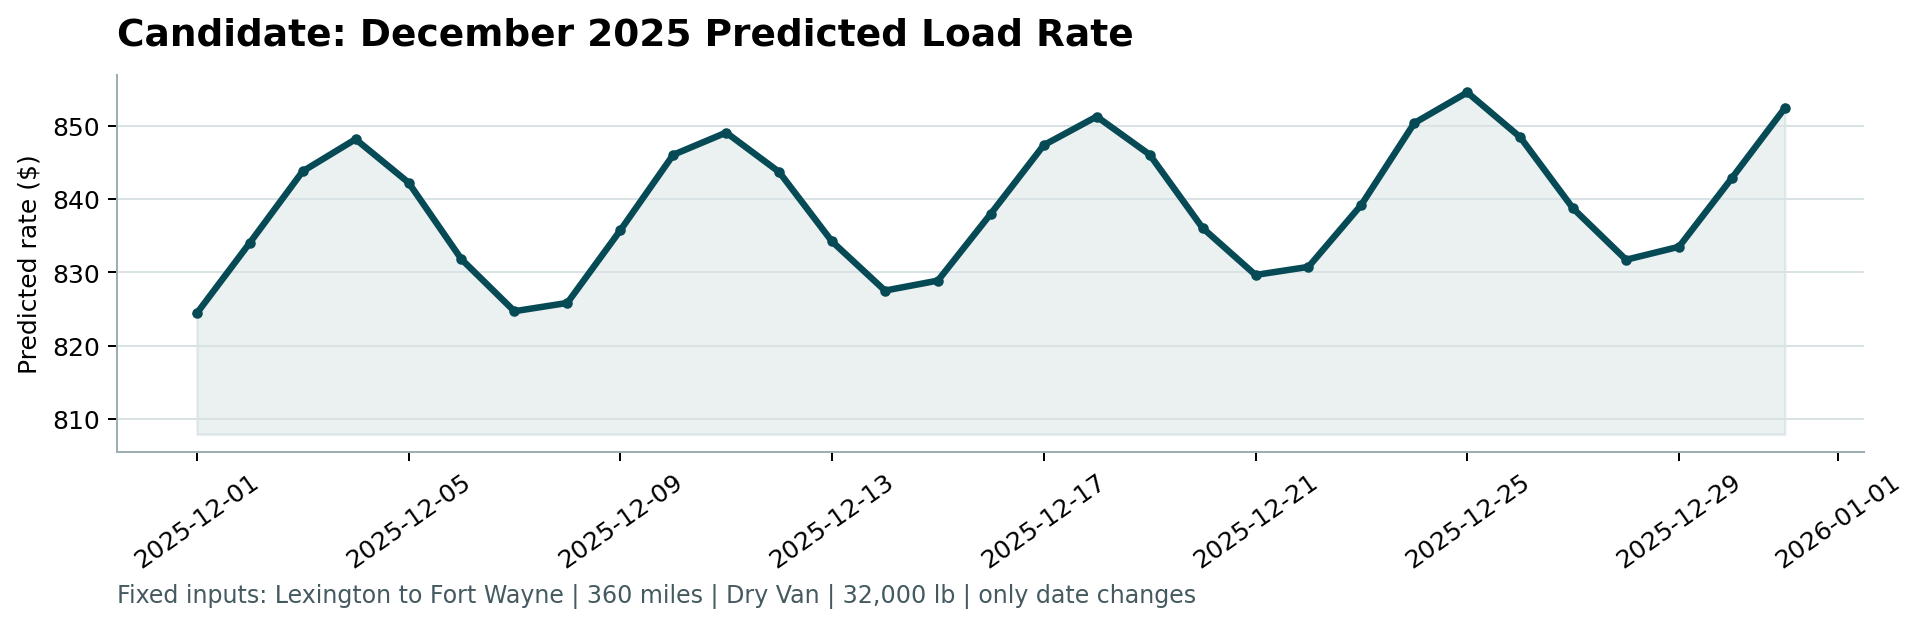

In [ ]:
# ============================================================
# CELL 10 (final) — PRODUCTION RUN: predictions + official scorer
#   A. shipped pipeline: time-free fit → 6×MADσ cleaning → refit on the clean rows
#   B. validation.csv (12,000 rows) → validation_predictions.csv (template order)
#   C. december-chart-inputs.csv → predicted_rate fill (same-period signal lookup)
#   D. run score.py → scorer_results/candidate_december.png (inline display)
# (standalone — does not need any variable from previous cells)
# ============================================================
import os, subprocess, sys
import numpy as np
import pandas as pd

def find(*names):
    for root in ("/content", "/content/data", "."):
        for n in names:
            p = os.path.join(root, n)
            if os.path.isfile(p):
                return p
    return None

TRAIN = find("train-test.csv", "train_test.csv")
VAL   = find("validation.csv")
TMPL  = find("validation-predictions-template.csv", "validation_predictions_template.csv")
DEC   = find("december-chart-inputs.csv", "december_chart_inputs.csv")
SCORE = find("score.py")
assert TRAIN and VAL and TMPL and DEC and SCORE, (TRAIN, VAL, TMPL, DEC, SCORE)
OUTDIR = os.path.dirname(os.path.abspath(TRAIN))
print("files:"); [print("   ", p) for p in (TRAIN, VAL, TMPL, DEC, SCORE)]

T0 = pd.Timestamp("2025-01-01")
train = pd.read_csv(TRAIN)
assert "posted_rate" in train.columns and "pickup" in train.columns, "train-test.csv signature mismatch"

# ---------- A. fit (shipped pipeline) ----------
train["weight"] = pd.to_numeric(train["weight"], errors="coerce").abs()
CITIES = sorted(train["pickup"].unique().tolist())
K = len(CITIES) - 1
CIDX = {c: i for i, c in enumerate(CITIES)}
MARKET_MED = float(train["market_index"].median())
QUOTE_MED  = float(train["quote_signal"].median())
WEIGHT_MED = float(train["weight"].median())
FEATS = ["ld", "ld2", "market", "quote", "log_w", "is_reefer", "is_flatbed"]

def base_frame(d, with_time):
    f = pd.DataFrame(index=d.index)
    f["ld"] = np.log(d["distance"].astype(float))
    f["ld2"] = f["ld"] ** 2
    f["market"] = (pd.to_numeric(d["market_index"], errors="coerce").fillna(MARKET_MED)
                   if "market_index" in d.columns else MARKET_MED)
    f["quote"] = (pd.to_numeric(d["quote_signal"], errors="coerce").fillna(QUOTE_MED)
                  if "quote_signal" in d.columns else QUOTE_MED)
    f["log_w"] = np.log(pd.to_numeric(d["weight"], errors="coerce").abs().fillna(WEIGHT_MED))
    f["is_reefer"] = (d["equipment"] == "Reefer").astype(float)
    f["is_flatbed"] = (d["equipment"] == "Flatbed").astype(float)
    if with_time:
        f["t"] = (pd.to_datetime(d["date"]) - T0).dt.days.astype(float)
    return f

def city_block(s):
    out = np.zeros((len(s), K))
    for r, c in enumerate(s.values):
        j = CIDX.get(c)
        if j is None:       # genuinely unseen city -> prior-mean effect
            out[r, :] = 1.0 / K
        elif j > 0:         # seen, non-baseline
            out[r, j - 1] = 1.0
    return out

def design(d, with_time=True):
    f = base_frame(d, with_time)
    cols = [np.ones((len(d), 1)),
            f[FEATS + (["t"] if with_time else [])].to_numpy(float)]
    cols.append(city_block(d["pickup"]))
    cols.append(city_block(d["delivery"]))
    return np.hstack(cols)

y_tr = np.log(train["posted_rate"].values.astype(float))
Xc = np.hstack([np.ones((len(train), 1)), base_frame(train, False)[FEATS].to_numpy(float)])
b0, *_ = np.linalg.lstsq(Xc, y_tr, rcond=None)
r0 = y_tr - Xc @ b0
SIGMA = 1.4826 * np.median(np.abs(r0 - np.median(r0)))
keep = np.abs(r0 - np.median(r0)) < 6 * SIGMA
coef, *_ = np.linalg.lstsq(design(train[keep]), y_tr[keep], rcond=None)
print(f"\ntrained on {int(keep.sum()):,} clean rows (flagged {int((~keep).sum())}, "
      f"{100*(~keep).mean():.2f}%) | MAD sigma {SIGMA:.5f} | k={len(coef)}")

def fill_signals(d, source):
    if source is None:
        return d
    out = d.copy()
    src = source.copy(); src["_d"] = pd.to_datetime(src["date"])
    dd = pd.to_datetime(out["date"])
    for col in ("market_index", "quote_signal"):
        daily = dd.map(src.groupby("_d")[col].median())
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce").fillna(daily)
        else:
            out[col] = daily
    return out

def predict(d, same_period=None):
    dd = fill_signals(d, same_period)
    return np.clip(np.exp(design(dd) @ coef), 25.0, 40_000.0)

# ---------- B. validation predictions ----------
val = pd.read_csv(VAL)
pred_val = np.round(predict(val, same_period=val), 2)
tmpl = pd.read_csv(TMPL)
out = tmpl[["load_id"]].merge(
    pd.DataFrame({"load_id": val["load_id"], "predicted_rate": pred_val}),
    on="load_id", how="left")
assert out["predicted_rate"].notna().all() and len(out) == 12000
pred_path = os.path.join(OUTDIR, "validation_predictions.csv")
out.to_csv(pred_path, index=False)
vdt = val["date"].astype(str)
print(f"\nvalidation predictions: {len(out):,} rows | mean ${out.predicted_rate.mean():,.2f} | "
      f"min ${out.predicted_rate.min():,.2f} | max ${out.predicted_rate.max():,.2f}")
print(f"  Nov rows: {int(vdt.str.startswith('2025-11').sum()):,} mean "
      f"${out.predicted_rate[vdt.str.startswith('2025-11').values].mean():,.2f} | "
      f"Dec rows: {int(vdt.str.startswith('2025-12').sum()):,} mean "
      f"${out.predicted_rate[vdt.str.startswith('2025-12').values].mean():,.2f}")
print(f"  saved -> {pred_path}")

# ---------- C. december chart inputs ----------
dec = pd.read_csv(DEC)
dec_filled = dec.copy()
dec_filled["predicted_rate"] = np.round(predict(dec, same_period=val), 2)
dec_path = os.path.join(OUTDIR, "december-chart-inputs-filled.csv")
dec_filled.to_csv(dec_path, index=False)
print(f"\ndecember predictions: {len(dec_filled)} rows | min ${dec_filled.predicted_rate.min():,.2f} | "
      f"max ${dec_filled.predicted_rate.max():,.2f} | mean ${dec_filled.predicted_rate.mean():,.2f}")
print(f"  saved -> {dec_path}")

# ---------- D. official scorer ----------
print("\n" + "=" * 70)
run = subprocess.run([sys.executable, SCORE, "--predictions", pred_path,
                      "--december-predictions", dec_path],
                     capture_output=True, text=True, cwd=OUTDIR)
print(run.stdout.strip())
if run.returncode != 0:
    print("STDERR:", run.stderr[-2000:])

chart = os.path.join(OUTDIR, "scorer_results", "candidate_december.png")
print("chart:", chart, "| exists:", os.path.exists(chart))
try:
    from IPython.display import Image, display
    display(Image(chart, width=980))
except Exception as e:
    print("(inline display skipped:", e, ")")
